# Entrenamiento del detector de eventos acústicos

Este notebook implementa la preparación de datos, entrenamiento, validación y evaluación de un modelo de Deep Learning para detectar eventos acústicos de aves mediante bounding boxes en espectrogramas

El detector es independiente de las especies, su objetivo es localizar cero, uno o múltiples eventos acústicos en una misma ventana. La identificación taxonómica se realizará posteriormente mediante un clasificador independiente

### Configuración inicial

Las decisiones de referencia proceden del análisis exploratorio realizado previamente:

- **Frecuencia de muestreo:** 32 kHz.
- **Duración inicial de ventana:** 8 segundos.
- **Rango frecuencial:** 0–16 kHz.
- **Partición:** 70 % entrenamiento, 15 % validación y 15 % prueba, agrupada por `recording_uid`.
- **Fuente de datos:** dataset público de Kaggle.

El entrenamiento se realizará en Google Colab mediante carga incremental de datos, checkpoints persistentes y recuperación ante interrupciones.

Las arquitecturas, el preprocesamiento espectral y los hiperparámetros se definirán y validarán antes del entrenamiento definitivo.

## Preparar el entorno

In [ ]:
%pip -q install "kagglehub>=1.0.0"

from pathlib import Path
import os
import json
import numpy as np
import pandas as pd
import torch
import soundfile as sf
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import requests
from matplotlib.patches import Rectangle
from scipy.signal import stft
from torch.utils.data import Dataset
from torch.utils.data import DataLoader, Subset
%pip -q install "torchmetrics[detection]>=1.4,<2"
import hashlib
import math
import random
import shutil
import tempfile
import time

import torchvision
from torchmetrics.detection.mean_ap import MeanAveragePrecision
from torchvision.models.detection import (fasterrcnn_mobilenet_v3_large_fpn, FasterRCNN_MobileNet_V3_Large_FPN_Weights)
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
import gc

import kagglehub

print("PyTorch:", torch.__version__)
print("GPU disponible:", torch.cuda.is_available())
print("KaggleHub:", kagglehub.__version__)

PyTorch: 2.11.0+cu130
GPU disponible: True
KaggleHub: 1.0.3


Montamos Google Drive, pero solo para guardar resultados persistentes

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

DATASET = "santiagocorrea802/dataset-proyecto"
KAGGLE_ROOT = "DATASET_PROYECTO"
BASE_LOCAL = Path("/content/proyecto_aves")
BASE_DRIVE = Path("/content/drive/MyDrive/Proyecto_Aves")
CHECKPOINT_DIR = BASE_DRIVE / "checkpoints" / "detector"
EXPERIMENTS_DIR = BASE_DRIVE / "experiments" / "detector"
BASE_LOCAL.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
EXPERIMENTS_DIR.mkdir(parents=True, exist_ok=True)

SAMPLE_RATE = 32000
WINDOW_S = 8
F_MIN = 0
F_MAX = 16000
SEED = 0

print("Dataset:", DATASET)
print("Datos temporales:", BASE_LOCAL)
print("Checkpoints:", CHECKPOINT_DIR)
print("Experimentos:", EXPERIMENTS_DIR)

Mounted at /content/drive
Dataset: santiagocorrea802/dataset-proyecto
Datos temporales: /content/proyecto_aves
Checkpoints: /content/drive/MyDrive/Proyecto_Aves/checkpoints/detector
Experimentos: /content/drive/MyDrive/Proyecto_Aves/experiments/detector


Usaremos:
- DATASET_PROYECTO/metadata/master_manifest.csv
- DATASET_PROYECTO/metadata/recordings_manifest.csv
- DATASET_PROYECTO/metadata/detector_manifest.csv

In [ ]:
def descargar_manifest(nombre):
    ruta_kaggle = f"{KAGGLE_ROOT}/metadata/{nombre}"
    ruta_local = BASE_LOCAL / ruta_kaggle

    if not ruta_local.is_file():
        ruta_local = Path(kagglehub.dataset_download(DATASET, path=ruta_kaggle, output_dir=str(BASE_LOCAL)))

    if not ruta_local.is_file():
        raise FileNotFoundError(f"No se pudo obtener: {ruta_kaggle}")

    return pd.read_csv(ruta_local)

master = descargar_manifest("master_manifest.csv")
recordings = descargar_manifest("recordings_manifest.csv")
detector = descargar_manifest("detector_manifest.csv")
columnas_requeridas = {"recording_uid", "normalized_path", "t_min", "t_max", "f_min", "f_max", "detector_label"}
faltantes = columnas_requeridas - set(detector.columns)

if faltantes:
    raise ValueError(f"Columnas faltantes en detector_manifest: {sorted(faltantes)}")

if not detector["detector_label"].eq("BIRD_EVENT").all():
    raise ValueError("Se encontraron etiquetas inesperadas para el detector")

if not set(detector["recording_uid"]).issubset(set(recordings["recording_uid"])):
    raise ValueError("Existen eventos sin grabación correspondiente")

print("Master:", master.shape)
print("Grabaciones:", recordings.shape)
print("Detector:", detector.shape)
print("Etiquetas detector:", detector["detector_label"].unique())
display(detector.head())

100%|██████████| 16.8M/16.8M [00:02<00:00, 6.74MB/s]


100%|██████████| 253k/253k [00:00<00:00, 305kB/s]


100%|██████████| 10.8M/10.8M [00:02<00:00, 5.01MB/s]


Master: (48465, 31)
Grabaciones: (1017, 22)
Detector: (48430, 15)
Etiquetas detector: ['BIRD_EVENT']


,event_id,dataset,recording,recording_uid,normalized_path,country,species_scientific,identified,t_min,t_max,f_min,f_max,duration_event_sec,bandwidth_hz,detector_label
0,PteroSet::0,PteroSet,G6455_20240218.wav,PteroSet::g6455_20240218,audio_32khz/pteroset/G6455_20240218.flac,Colombia,ortalis guttata,True,120.966525,126.301426,0.0,2647.7,5.334901,2647.7,BIRD_EVENT
1,PteroSet::1,PteroSet,G6455_20240218.wav,PteroSet::g6455_20240218,audio_32khz/pteroset/G6455_20240218.flac,Colombia,cyanocorax violaceus,True,126.355988,128.580884,2220.6,4099.6,2.224896,1879.0,BIRD_EVENT
2,PteroSet::2,PteroSet,G6455_20240218.wav,PteroSet::g6455_20240218,audio_32khz/pteroset/G6455_20240218.flac,Colombia,cyanocorax violaceus,True,130.762386,132.096112,1622.8,4099.6,1.333725,2476.8,BIRD_EVENT
3,PteroSet::3,PteroSet,G6455_20240218.wav,PteroSet::g6455_20240218,audio_32khz/pteroset/G6455_20240218.flac,Colombia,sclateria naevia,True,141.893880,144.943261,4185.1,5807.8,3.049381,1622.7,BIRD_EVENT
4,PteroSet::4,PteroSet,G6455_20240218.wav,PteroSet::g6455_20240218,audio_32khz/pteroset/G6455_20240218.flac,Colombia,sclateria naevia,True,156.766264,159.870206,3160.1,16000.0,3.103943,12839.9,BIRD_EVENT


Recordemos, detector solo cuenta con muestras con geometria válida

## Reproducir Split obtenido en el EDA

In [ ]:
grabaciones_base = master[["recording_uid", "dataset"]].drop_duplicates(subset=["recording_uid"]).copy()
train_rec, temp_rec = train_test_split(grabaciones_base, test_size=0.30, random_state=SEED, stratify=grabaciones_base["dataset"] )
val_rec, test_rec = train_test_split(temp_rec, test_size=0.50, random_state=SEED,stratify=temp_rec["dataset"])

train_rec = train_rec.copy()
val_rec = val_rec.copy()
test_rec = test_rec.copy()

train_rec["split"] = "train"
val_rec["split"] = "validation"
test_rec["split"] = "test"
grabaciones_split = pd.concat([train_rec, val_rec, test_rec], ignore_index=True)
print("Grabaciones:", len(grabaciones_split))
print(grabaciones_split["split"].value_counts())

Grabaciones: 1011
split
train         707
validation    152
test          152
Name: count, dtype: int64


Validamos split y asignamos eventos

In [ ]:
train_ids = set(grabaciones_split.loc[grabaciones_split["split"] == "train", "recording_uid"])
val_ids = set(grabaciones_split.loc[grabaciones_split["split"] == "validation", "recording_uid"])
test_ids = set(grabaciones_split.loc[grabaciones_split["split"] == "test", "recording_uid"])

assert len(train_ids & val_ids) == 0, "Leakage entre train y validation"
assert len(train_ids & test_ids) == 0, "Leakage entre train y test"
assert len(val_ids & test_ids) == 0, "Leakage entre validation y test"
assert (len(train_ids), len(val_ids), len(test_ids)) == (707, 152, 152), "El split difiere del EDA"

detector_split = detector.merge(grabaciones_split[["recording_uid", "split"]], on="recording_uid", how="left", validate="many_to_one")
assert detector_split["split"].notna().all(), "Existen eventos sin split"
assert len(detector_split) == len(detector), "Se modificó la cantidad de eventos"

especies_objetivo = master.loc[(master["is_target"] == True) & (master["use_detector"] == True), "species_scientific"].dropna().unique()
cobertura = detector_split[detector_split["species_scientific"].isin(especies_objetivo)].groupby(["species_scientific", "split"])["recording_uid"].nunique().unstack(fill_value=0)
cobertura = cobertura.reindex(index=especies_objetivo, columns=["train", "validation", "test"], fill_value=0)
assert (cobertura > 0).all().all(), "Hay especies objetivo ausentes en algún split"

resumen_split = grabaciones_split.groupby(["split", "dataset"]).size().unstack(fill_value=0)
resumen_split = resumen_split.reindex(["train", "validation", "test"])
resumen_split["Total"] = resumen_split.sum(axis=1)
display(resumen_split)
print("Eventos del detector:", len(detector_split))
print("Especies objetivo:", len(especies_objetivo))
print("Leakage por recording_uid: 0")
print("Todas las especies objetivo representadas:", True)

dataset,Col-CR,Peru,PteroSet,WABAD-CO,Total
split,,,,,
train,24,14,394,275,707
validation,5,3,85,59,152
test,5,4,84,59,152


Eventos del detector: 48430
Especies objetivo: 30
Leakage por recording_uid: 0
Todas las especies objetivo representadas: True


**GUARDEMOS ESTE SPLIT**

In [ ]:
SPLIT_DIR = BASE_DRIVE / "splits"
SPLIT_DIR.mkdir(parents=True, exist_ok=True)
SPLIT_PATH = SPLIT_DIR / "recording_split_seed0.csv"
split_final = grabaciones_split[["recording_uid", "dataset", "split"]].sort_values("recording_uid").reset_index(drop=True)

if SPLIT_PATH.exists():
    split_guardado = pd.read_csv(SPLIT_PATH).sort_values("recording_uid").reset_index(drop=True)
    if not split_final.equals(split_guardado):
        raise ValueError("El split guardado es diferente. No se sobrescribirá")
    print("El split ya existe y coincide con el actual")
else:
    split_final.to_csv(SPLIT_PATH, index=False)
    print("Split guardado por primera vez")

split_verificado = pd.read_csv(SPLIT_PATH).sort_values("recording_uid").reset_index(drop=True)
assert split_final.equals(split_verificado), "Error al verificar el archivo guardado"

print("Ruta:", SPLIT_PATH)
print("Grabaciones guardadas:", len(split_verificado))

El split ya existe y coincide con el actual
Ruta: /content/drive/MyDrive/Proyecto_Aves/splits/recording_split_seed0.csv
Grabaciones guardadas: 1011


## comprobar que podemos transformar las anotaciones de un audio real en bounding boxes correctamente posicionados sobre un espectrograma de 8 segundos.

Seleccionar y descargar una grabación

Utilizaremos detector_split para seleccionar una grabación del conjunto train. Elegiremos una relativamente corta, con al menos dos eventos anotados, para evitar una descarga innecesariamente grande.

In [ ]:
resumen_eventos = detector_split.groupby("recording_uid").agg(n_eventos=("event_id", "size"), normalized_path=("normalized_path", "first")).reset_index()
candidatos = grabaciones_split[grabaciones_split["split"] == "train"].merge(recordings[["recording_uid", "duration_sec"]], on="recording_uid", how="inner").merge(resumen_eventos, on="recording_uid", how="inner")
candidatos = candidatos[(candidatos["duration_sec"] >= WINDOW_S) & (candidatos["n_eventos"] >= 2)].sort_values(["duration_sec", "n_eventos"], ascending=[True, False])
if candidatos.empty:
    raise ValueError("No se encontraron grabaciones apropiadas para la prueba")

ejemplo = candidatos.iloc[0]
ruta_relativa = str(ejemplo["normalized_path"]).replace("\\", "/")
ruta_kaggle = f"{KAGGLE_ROOT}/{ruta_relativa}"
ruta_local = BASE_LOCAL / ruta_kaggle

if ruta_local.is_file():
    ruta_audio = ruta_local
else:
    ruta_audio = Path(kagglehub.dataset_download(DATASET, path=ruta_kaggle, output_dir=str(BASE_LOCAL)))

if not ruta_audio.is_file():
    raise FileNotFoundError(f"No se pudo descargar: {ruta_kaggle}")

print("Grabación:", ejemplo["recording_uid"])
print("Dataset:", ejemplo["dataset"])
print("Duración:", round(ejemplo["duration_sec"], 2), "s")
print("Eventos anotados:", ejemplo["n_eventos"])
print("Archivo:", ruta_audio)
print("Tamaño:", round(ruta_audio.stat().st_size / 1024**2, 2), "MB")

100%|██████████| 2.49M/2.49M [00:01<00:00, 1.57MB/s]

Grabación: WABAD-CO::bre_20071211_060006
Dataset: WABAD-CO
Duración: 60.0 s
Eventos anotados: 63
Archivo: /content/proyecto_aves/DATASET_PROYECTO/audio_32khz/wabad_co/BRE_20071211_060006.flac
Tamaño: 2.49 MB


**EXTRAER UNA VENTANA DE 8 SEGUNDOS Y SUS BOUNDING BOXES**

In [ ]:
info = sf.info(ruta_audio)
if info.samplerate != SAMPLE_RATE or info.channels != 1:
    raise ValueError(f"Audio incompatible: {info.samplerate} Hz, {info.channels} canales")

n_muestras = SAMPLE_RATE * WINDOW_S
if info.frames < n_muestras:
    raise ValueError("La grabación es más corta que la ventana solicitada")

eventos_grabacion = detector_split[detector_split["recording_uid"] == ejemplo["recording_uid"]].sort_values("t_min").copy()
eventos_validos = eventos_grabacion[(eventos_grabacion["t_min"] < info.duration) & (eventos_grabacion["t_max"] > 0)]

if eventos_validos.empty:
    raise ValueError("No hay eventos dentro de la duración real del audio")

ancla = eventos_validos.iloc[0]
centro = (ancla["t_min"] + ancla["t_max"]) / 2
#np.clip(x,a,b) = min(max(x,a),b)
inicio_muestra = int(np.clip(round((centro - WINDOW_S / 2) * SAMPLE_RATE), 0, info.frames - n_muestras))
                                                                            # N_audio - N_ventana

# convertimos a segundos
inicio = inicio_muestra / SAMPLE_RATE
fin = inicio + WINDOW_S

with sf.SoundFile(ruta_audio) as archivo:
    archivo.seek(inicio_muestra) # parametro como frame o muestra, no en segundos
    audio = archivo.read(n_muestras, dtype="float32")

# no tomamos eventos que empiecen luego del tiempo maximo
cajas_ventana = eventos_grabacion[(eventos_grabacion["t_min"] < fin) & (eventos_grabacion["t_max"] > inicio)].copy()
cajas_ventana["truncada"] = ((cajas_ventana["t_min"] < inicio) | (cajas_ventana["t_max"] > fin))

# Las anotaciones están en segundos con respecto al audio original
# necesitamos que estén en segundos con respecto a la ventana
# nuevo t_min = max(0, t_min - inicioventana)
# nuevo t_max = min(duracion_ventana, t_max - inicioventana)
cajas_ventana["t_min_local"] = (cajas_ventana["t_min"] - inicio).clip(0, WINDOW_S)
cajas_ventana["t_max_local"] = (cajas_ventana["t_max"] - inicio).clip(0, WINDOW_S)

print("Ventana:", round(inicio, 3), "-", round(fin, 3), "s")
print("Muestras:", len(audio))
print("Eventos presentes:", len(cajas_ventana))
print("Cajas truncadas:", int(cajas_ventana["truncada"].sum()))
display(cajas_ventana[["event_id", "species_scientific", "t_min_local", "t_max_local", "f_min", "f_max", "truncada"]])

Ventana: 0.0 - 8.0 s
Muestras: 256000
Eventos presentes: 10
Cajas truncadas: 2


,event_id,species_scientific,t_min_local,t_max_local,f_min,f_max,truncada
40234,WABAD-CO::14163,colibri cyanotus,0.408398,3.069176,5348.298,7740.957,False
40252,WABAD-CO::14181,empidonax virescens,1.039560,1.237571,2478.096,6321.674,False
40281,WABAD-CO::14210,arremon brunneinucha,2.202876,3.415696,9002.064,11176.720,False
40253,WABAD-CO::14182,empidonax virescens,2.252379,2.450390,2478.096,6119.381,False
40235,WABAD-CO::14164,colibri cyanotus,3.576580,6.521999,5158.486,7383.716,False
40282,WABAD-CO::14211,arremon brunneinucha,4.071608,5.086416,9356.078,11126.147,False
40254,WABAD-CO::14183,empidonax virescens,4.418128,4.591388,2730.963,6169.954,False
40283,WABAD-CO::14212,arremon brunneinucha,6.571502,8.000000,8496.330,10620.413,True
40236,WABAD-CO::14165,colibri cyanotus,7.190287,8.000000,5360.780,7383.716,True
40255,WABAD-CO::14184,empidonax virescens,7.338795,7.536807,2579.243,5967.661,False


Las anotaciones originales están expresadas respecto al inicio de la grabación completa.
Por ejemplo, si tenemos un evento entre 124 y 126 segundos, pero nuestra ventana empieza en el segundo 120:

$t_{\min,\text{local}}=124-120=4\text{ s}$

$t_{\max,\text{local}}=126-120=6\text{ s}$

Entonces la caja deberá dibujarse entre los segundos 4 y 6 del espectrograma.

**Visualizar espectograma y bounding boxes**

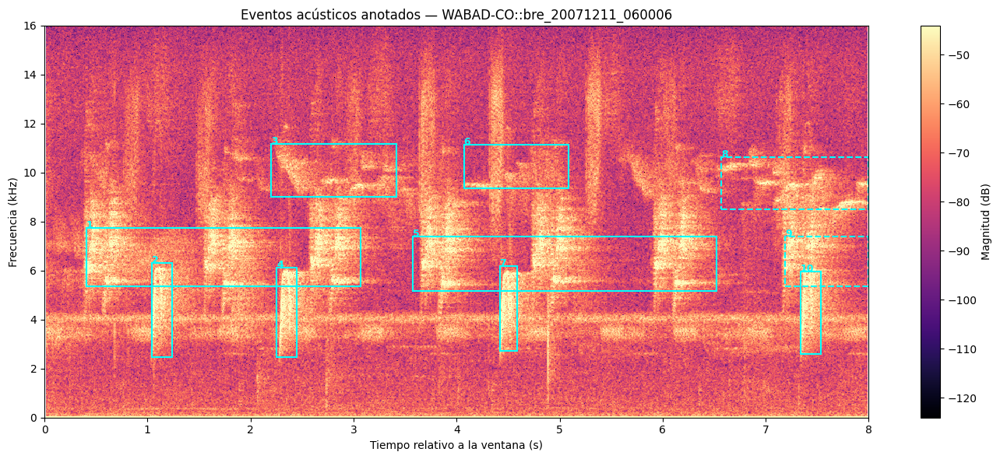

In [ ]:
frecuencias, tiempos, Z = stft(audio, fs=SAMPLE_RATE, nperseg=1024, noverlap=768, boundary=None)
# formula fundamental de aplicar logaritmo sobre una magnitud de amplitud
espectrograma_db = 20 * np.log10(np.maximum(np.abs(Z), 1e-8))
vmax = np.percentile(espectrograma_db, 99)

fig, ax = plt.subplots(figsize=(14, 6))
imagen = ax.pcolormesh(tiempos, frecuencias / 1000, espectrograma_db, shading="auto", cmap="magma", vmin=vmax - 80, vmax=vmax)

for i, caja in enumerate(cajas_ventana.itertuples(), start=1):
    x = caja.t_min_local
    y = caja.f_min / 1000
    ancho = caja.t_max_local - caja.t_min_local
    alto = (caja.f_max - caja.f_min) / 1000
    rectangulo = Rectangle((x, y), ancho, alto, linewidth=1.5, edgecolor="cyan", facecolor="none", linestyle="--" if caja.truncada else "-")
    ax.add_patch(rectangulo)
    ax.text(x, min(y + alto, 15.8), str(i), color="cyan", fontsize=9, fontweight="bold")

ax.set_xlim(0, WINDOW_S)
ax.set_ylim(0, F_MAX / 1000)
ax.set_xlabel("Tiempo relativo a la ventana (s)")
ax.set_ylabel("Frecuencia (kHz)")
ax.set_title(f"Eventos acústicos anotados — {ejemplo['recording_uid']}")
fig.colorbar(imagen, ax=ax, label="Magnitud (dB)")
plt.tight_layout()
plt.show()

## Segmentación temporal de grabaciones

Las grabaciones se dividirán inicialmente mediante ventanas deslizantes de 8 segundos, con un desplazamiento de 4 segundos (50% de solapamiento).

Las anotaciones originales serán transformadas a coordenadas locales respecto al inicio de cada ventana. Los eventos que crucen sus límites se representarán mediante bounding boxes recortados, conservando información sobre la proporción temporal visible.

La misma estrategia será inicialmente utilizada en entrenamiento, validación, prueba e inferencia. Posteriormente podrán evaluarse otras estrategias de muestreo para entrenamiento.

Las ventanas sin eventos anotados no se considerarán automáticamente ejemplos negativos confirmados.

**Generar las ventanas de una grabación**, Usaremos el audio de 60 segundos que ya descargamos. La función generará las ventanas sin leer todo el audio, usando su número de muestras.

In [ ]:
SOLAPAMIENTO_S = 4
SALTO_S = WINDOW_S - SOLAPAMIENTO_S

def generar_ventanas(n_muestras, fs=SAMPLE_RATE, ventana_s=WINDOW_S, salto_s=SALTO_S):
    tam_ventana = round(ventana_s * fs)
    tam_salto = round(salto_s * fs)

    if tam_salto <= 0 or tam_ventana <= 0:
        raise ValueError("La ventana y el salto deben ser positivos")
    if n_muestras < tam_ventana:
        raise ValueError("Audio menor que la ventana; requiere una política de padding")

    ultimo_inicio = n_muestras - tam_ventana
    inicios = list(range(0, ultimo_inicio + 1, tam_salto))

    if inicios[-1] != ultimo_inicio:
        diferencia = ultimo_inicio - inicios[-1]

        # Si el desplazamiento final es pequeño y no deja huecos, ajustar la ultima ventana existente
        if (
            len(inicios) > 1
            and diferencia <= tam_salto / 2
            and ultimo_inicio - inicios[-2] <= tam_ventana
        ):
            inicios[-1] = ultimo_inicio
        else:
            inicios.append(ultimo_inicio)

    return pd.DataFrame([{
            "ventana_id": i,
            "inicio_muestra": s,
            "fin_muestra": s + tam_ventana,
            "inicio_s": s / fs,
            "fin_s": (s + tam_ventana) / fs
        } for i, s in enumerate(inicios)
    ])

ventanas = generar_ventanas(info.frames)
print("Duración del audio:", round(info.duration, 2), "s")
print("Ventanas generadas:", len(ventanas))
print("Duración por ventana:", WINDOW_S, "s")
print("Desplazamiento:", SALTO_S, "s")
display(ventanas)

Duración del audio: 60.0 s
Ventanas generadas: 14
Duración por ventana: 8 s
Desplazamiento: 4 s


,ventana_id,inicio_muestra,fin_muestra,inicio_s,fin_s
0,0,0,256000,0.000000,8.000000
1,1,128000,384000,4.000000,12.000000
2,2,256000,512000,8.000000,16.000000
3,3,384000,640000,12.000000,20.000000
4,4,512000,768000,16.000000,24.000000
5,5,640000,896000,20.000000,28.000000
6,6,768000,1024000,24.000000,32.000000
7,7,896000,1152000,28.000000,36.000000
8,8,1024000,1280000,32.000000,40.000000
9,9,1152000,1408000,36.000000,44.000000


**Asignar los bounding boxes a cada ventana**:

Una misma anotación puede aparecer en varias ventanas, por ejemplo, el evento entre 7 y 10 segundos intersecta tanto la ventana 0–8 como la ventana 4–12, debemos calcular cuánto queda visible en cada una y transformar sus coordenadas temporales.

In [ ]:
anotaciones_ventanas = []

for ventana in ventanas.itertuples(index=False):
    inicio, fin = ventana.inicio_s, ventana.fin_s
    eventos = eventos_grabacion[(eventos_grabacion["t_min"] < fin) & (eventos_grabacion["t_max"] > inicio)].copy()

    if eventos.empty:
        continue

    eventos["ventana_id"] = ventana.ventana_id
    eventos["t_min_local"] = (eventos["t_min"] - inicio).clip(0, WINDOW_S)
    eventos["t_max_local"] = (eventos["t_max"] - inicio).clip(0, WINDOW_S)
    eventos["truncada"] = ((eventos["t_min"] < inicio) | (eventos["t_max"] > fin))
    eventos["fraccion_visible"] = ((eventos["t_max_local"] - eventos["t_min_local"]) / (eventos["t_max"] - eventos["t_min"]))
    anotaciones_ventanas.append(eventos)

cajas_segmentadas = pd.concat(anotaciones_ventanas, ignore_index=True) if anotaciones_ventanas else pd.DataFrame()
resumen_ventanas = ventanas[["ventana_id", "inicio_s", "fin_s"]].copy()
if not cajas_segmentadas.empty:
    conteos = cajas_segmentadas.groupby("ventana_id").agg(n_eventos=("event_id", "size"), n_truncadas=("truncada", "sum"))
    resumen_ventanas = resumen_ventanas.join(conteos, on="ventana_id")

resumen_ventanas[["n_eventos", "n_truncadas"]] = (resumen_ventanas.reindex(columns=["n_eventos", "n_truncadas"])[["n_eventos", "n_truncadas"]].fillna(0).astype(int))


print("Ventanas totales:", len(resumen_ventanas))
print("Ventanas con anotaciones:", (resumen_ventanas["n_eventos"] > 0).sum())
print("Ventanas sin anotaciones:", (resumen_ventanas["n_eventos"] == 0).sum())
print("Cajas asignadas (contando repeticiones):", len(cajas_segmentadas))
print("Eventos originales representados:", cajas_segmentadas["event_id"].nunique() if not cajas_segmentadas.empty else 0)
display(resumen_ventanas)
display(cajas_segmentadas[["ventana_id", "event_id", "species_scientific", "t_min_local", "t_max_local", "fraccion_visible", "truncada"]].head(15))

Ventanas totales: 14
Ventanas con anotaciones: 14
Ventanas sin anotaciones: 0
Cajas asignadas (contando repeticiones): 136
Eventos originales representados: 63


,ventana_id,inicio_s,fin_s,n_eventos,n_truncadas
0,0,0.000000,8.000000,10,2
1,1,4.000000,12.000000,11,3
2,2,8.000000,16.000000,11,3
3,3,12.000000,20.000000,11,2
4,4,16.000000,24.000000,11,3
5,5,20.000000,28.000000,10,2
6,6,24.000000,32.000000,10,3
7,7,28.000000,36.000000,10,4
8,8,32.000000,40.000000,11,2
9,9,36.000000,44.000000,11,2


,ventana_id,event_id,species_scientific,t_min_local,t_max_local,fraccion_visible,truncada
0,0,WABAD-CO::14163,colibri cyanotus,0.408398,3.069176,1.000000,False
1,0,WABAD-CO::14181,empidonax virescens,1.039560,1.237571,1.000000,False
2,0,WABAD-CO::14210,arremon brunneinucha,2.202876,3.415696,1.000000,False
3,0,WABAD-CO::14182,empidonax virescens,2.252379,2.450390,1.000000,False
4,0,WABAD-CO::14164,colibri cyanotus,3.576580,6.521999,1.000000,False
5,0,WABAD-CO::14211,arremon brunneinucha,4.071608,5.086416,1.000000,False
6,0,WABAD-CO::14183,empidonax virescens,4.418128,4.591388,1.000000,False
7,0,WABAD-CO::14212,arremon brunneinucha,6.571502,8.000000,0.699561,True
8,0,WABAD-CO::14165,colibri cyanotus,7.190287,8.000000,0.307172,True
9,0,WABAD-CO::14184,empidonax virescens,7.338795,7.536807,1.000000,False


**Reconstruir el split y recuperar catalogo de grabaciones**

recuperar las asignaciones persistentes de Drive y reunir, para cada grabación, su partición, duración y ruta de audio.

In [ ]:
splits_fijos = pd.read_csv(SPLIT_PATH)
rutas = master[["recording_uid", "normalized_path"]].drop_duplicates()
catalogo = (splits_fijos.merge(recordings[["recording_uid", "duration_sec"]], on="recording_uid", how="left", validate="one_to_one").merge(
        rutas,
        on="recording_uid",
        how="left",
        validate="one_to_one"
    ))

print("Grabaciones en el catálogo:", len(catalogo))
print("\nValores faltantes por columna:")
print(catalogo[["duration_sec", "normalized_path"]].isna().sum())

faltantes_catalogo = catalogo[catalogo[["duration_sec", "normalized_path"]].isna().any(axis=1)]
if not faltantes_catalogo.empty:
    display(faltantes_catalogo)
    raise ValueError("El catálogo contiene grabaciones sin duración o ruta")

print("\nCatálogo construido correctamente")
print("Grabaciones:", len(catalogo))
display(catalogo.head())

Grabaciones en el catálogo: 1011

Valores faltantes por columna:
duration_sec       0
normalized_path    0
dtype: int64

Catálogo construido correctamente
Grabaciones: 1011


,recording_uid,dataset,split,duration_sec,normalized_path
0,Col-CR::nes_001_s01_20190914_043000,Col-CR,test,3600.000000,audio_32khz/colcr/NES_001_S01_20190914_043000....
1,Col-CR::nes_002_s01_20190914_043000,Col-CR,train,3600.000000,audio_32khz/colcr/NES_002_S01_20190914_043000....
2,Col-CR::nes_003_s01_20190914_053000,Col-CR,train,3600.000000,audio_32khz/colcr/NES_003_S01_20190914_053000....
3,Col-CR::nes_004_s01_20190914_063001,Col-CR,test,3599.018188,audio_32khz/colcr/NES_004_S01_20190914_063001....
4,Col-CR::nes_005_s01_20190914_063001,Col-CR,test,3598.932875,audio_32khz/colcr/NES_005_S01_20190914_063001....


**Construir el índice de ventanas de todo el corpus**

Usamos generar_ventanas() que ya se habia definido, pero en lugar de aplicarla a una sola grabación, se recorren todas las grabaciones.

Para archivos inferiores a ocho segundos prepararemos una ventana con información sobre cuánto padding necesitaría, todavía no generaremos ese padding solo registraremos su longitud.

In [ ]:
def construir_indice_ventanas(catalogo):
    registros = []
    tam_ventana = round(WINDOW_S * SAMPLE_RATE)

    for grabacion in catalogo.itertuples(index=False):
        n_estimadas = round(grabacion.duration_sec * SAMPLE_RATE)
        if n_estimadas < tam_ventana:
            inicios = [0]
        else:
            inicios = generar_ventanas(n_estimadas)["inicio_muestra"].tolist()
        for ventana_id, inicio_muestra in enumerate(inicios):
            fin_muestra = inicio_muestra + tam_ventana
            muestras_validas = max(0, min(n_estimadas, fin_muestra) - inicio_muestra)
            registros.append({
                "recording_uid": grabacion.recording_uid,
                "dataset": grabacion.dataset,
                "split": grabacion.split,
                "normalized_path": grabacion.normalized_path,
                "ventana_id": ventana_id,
                "inicio_muestra": inicio_muestra,
                "fin_muestra": fin_muestra,
                "inicio_s": inicio_muestra / SAMPLE_RATE,
                "fin_s": fin_muestra / SAMPLE_RATE,
                "padding_derecha_muestras": tam_ventana - muestras_validas
            })

    return pd.DataFrame.from_records(registros)

indice_ventanas = construir_indice_ventanas(catalogo)
print("Grabaciones indexadas:", indice_ventanas["recording_uid"].nunique())
print("Ventanas generadas:", len(indice_ventanas))
print("Ventanas que requieren padding:", (indice_ventanas["padding_derecha_muestras"] > 0).sum())
display(indice_ventanas.groupby("split").agg(grabaciones=("recording_uid", "nunique"), ventanas=("ventana_id", "size")))
display(indice_ventanas.head())

Grabaciones indexadas: 1011
Ventanas generadas: 120615
Ventanas que requieren padding: 0


,grabaciones,ventanas
split,,
test,152,18783
train,707,83870
validation,152,17962


,recording_uid,dataset,split,normalized_path,ventana_id,inicio_muestra,fin_muestra,inicio_s,fin_s,padding_derecha_muestras
0,Col-CR::nes_001_s01_20190914_043000,Col-CR,test,audio_32khz/colcr/NES_001_S01_20190914_043000....,0,0,256000,0.0,8.0,0
1,Col-CR::nes_001_s01_20190914_043000,Col-CR,test,audio_32khz/colcr/NES_001_S01_20190914_043000....,1,128000,384000,4.0,12.0,0
2,Col-CR::nes_001_s01_20190914_043000,Col-CR,test,audio_32khz/colcr/NES_001_S01_20190914_043000....,2,256000,512000,8.0,16.0,0
3,Col-CR::nes_001_s01_20190914_043000,Col-CR,test,audio_32khz/colcr/NES_001_S01_20190914_043000....,3,384000,640000,12.0,20.0,0
4,Col-CR::nes_001_s01_20190914_043000,Col-CR,test,audio_32khz/colcr/NES_001_S01_20190914_043000....,4,512000,768000,16.0,24.0,0


Asociar las 120.615 ventanas con los bounding boxes de sus correspondientes grabaciones

In [ ]:
# Ajustar las anotaciones al final de cada grabacionm
duraciones = catalogo.set_index("recording_uid")["duration_sec"]
detector_ajustado = detector_split.copy()
limites = detector_ajustado["recording_uid"].map(duraciones)
corregidas = detector_ajustado["t_max"] > limites
detector_ajustado.loc[corregidas, "t_max"] = limites[corregidas]

print("Anotaciones corregidas:", corregidas.sum())

# Asociar los eventos corregidos con las ventanas
ventanas_por_audio = {
    uid: grupo.sort_values("inicio_s").reset_index(drop=True)
    for uid, grupo in indice_ventanas.groupby("recording_uid")
}

registros = []

for evento in detector_ajustado.itertuples(index=False):
    grupo = ventanas_por_audio[evento.recording_uid]
    inicios = grupo["inicio_s"].to_numpy()
    finales = grupo["fin_s"].to_numpy()
    primero = np.searchsorted(finales, evento.t_min, side="right")
    ultimo = np.searchsorted(inicios, evento.t_max, side="left")

    for j in range(primero, ultimo):
        ventana = grupo.iloc[j]
        t0 = max(evento.t_min, ventana.inicio_s)
        t1 = min(evento.t_max, ventana.fin_s)
        if t1 <= t0:
            continue
        registros.append({
            "recording_uid": evento.recording_uid,
            "ventana_id": ventana.ventana_id,
            "event_id": evento.event_id,
            "t_min_local": t0 - ventana.inicio_s,
            "t_max_local": t1 - ventana.inicio_s,
            "f_min": evento.f_min,
            "f_max": evento.f_max,
            "fraccion_visible": (t1 - t0) / (evento.t_max - evento.t_min)
        })

anotaciones_por_ventana = pd.DataFrame(registros)
assert anotaciones_por_ventana["event_id"].nunique() == len(detector_ajustado)
print("Cajas asignadas:", len(anotaciones_por_ventana))
print("Eventos originales representados:", anotaciones_por_ventana["event_id"].nunique())
display(anotaciones_por_ventana.head())

Anotaciones corregidas: 30
Cajas asignadas: 147948
Eventos originales representados: 48430


,recording_uid,ventana_id,event_id,t_min_local,t_max_local,f_min,f_max,fraccion_visible
0,PteroSet::g6455_20240218,29,PteroSet::0,4.966525,8.000000,0.0,2647.7,0.568609
1,PteroSet::g6455_20240218,30,PteroSet::0,0.966525,6.301426,0.0,2647.7,1.000000
2,PteroSet::g6455_20240218,31,PteroSet::0,0.000000,2.301426,0.0,2647.7,0.431391
3,PteroSet::g6455_20240218,30,PteroSet::1,6.355988,8.000000,2220.6,4099.6,0.738916
4,PteroSet::g6455_20240218,31,PteroSet::1,2.355988,4.580884,2220.6,4099.6,1.000000


Durante la validación temporal se identificaron 30 anotaciones que excedían la duración de sus grabaciones. Se decidió ajustar sus tiempos finales al límite del audio, conservando todos los eventos, independientemente de la fracción temporal restante. Las anotaciones originales permanecen intactas y la corrección se aplica durante la preparación de los datos del detector.

## Crear BirdEventDataset


Implementaremos un Dataset personalizado de PyTorch para cargar fragmentos de audio, calcular sus espectrogramas y recuperar los bounding boxes correspondientes. Inicialmente trabajaremos con ventanas que contienen anotaciones, sin excluir aquellas cuyos eventos fueron corregidos temporalmente

In [ ]:
class BirdEventDataset(Dataset):

    def __init__(self, split):
        # Seleccionar ventanas con anotaciones y sin anomalia
        disponibles = indice_ventanas.loc[indice_ventanas["split"] == split].copy()
        claves = anotaciones_por_ventana[["recording_uid", "ventana_id"]].drop_duplicates()
        self.ventanas = disponibles.merge(claves, on=["recording_uid", "ventana_id"], how="inner", validate="one_to_one").reset_index(drop=True)

        # Organizar las cajas por grabación y ventana.
        self.cajas = {
            (uid, int(vid)): grupo[["t_min_local", "f_min", "t_max_local", "f_max"]].to_numpy(dtype=np.float32)
            for (uid, vid), grupo in anotaciones_por_ventana.groupby(["recording_uid", "ventana_id"])
        }

        if self.ventanas.empty:
            raise ValueError(f"No hay ventanas anotadas para {split}")

    def __len__(self):
        return len(self.ventanas)

    def __getitem__(self, idx):
        fila = self.ventanas.iloc[idx]

        # localizar o descargar el flac
        ruta_relativa = str(fila.normalized_path).replace("\\", "/")
        ruta_kaggle = f"{KAGGLE_ROOT}/{ruta_relativa}"
        ruta = BASE_LOCAL / ruta_kaggle

        if not ruta.is_file():
            for intento in range(4):
                try:
                    ruta = Path(kagglehub.dataset_download(DATASET, path=ruta_kaggle, output_dir=str(BASE_LOCAL)))
                    break
                except (requests.exceptions.Timeout, requests.exceptions.ConnectionError) as e:
                    if intento == 3:
                        raise

                    espera = 2 ** (intento + 1)
                    print(f"Error temporal de descarga. Reintentando en {espera} segundos...")
                    time.sleep(espera)

        # leer unicamente las muestras necesarias
        tam = SAMPLE_RATE * WINDOW_S

        with sf.SoundFile(ruta) as archivo:
            if archivo.samplerate != SAMPLE_RATE or archivo.channels != 1:
                raise ValueError(f"Formato de audio incompatible: {ruta}")

            archivo.seek(int(fila.inicio_muestra))
            audio = archivo.read(tam, dtype="float32")

        faltantes = tam - len(audio)
        if faltantes > 1:
            raise ValueError(f"Ventana fuera del audio real: {ruta}")

        if faltantes:
            audio = np.pad(audio, (0, faltantes))

        # Calcular el espectrograma
        _, _, Z = stft(audio, fs=SAMPLE_RATE, nperseg=1024, noverlap=768, boundary=None)
        db = 20 * np.log10(np.maximum(np.abs(Z), 1e-8))

        # normalzacion provisional de la imagen
        vmax = np.percentile(db, 99)
        espectrograma = np.clip((db - (vmax - 80)) / 80, 0, 1).astype(np.float32)

        # recuperar y normalizar los bounding boxes
        clave = (fila.recording_uid, int(fila.ventana_id))
        cajas = self.cajas[clave].copy()
        cajas /= np.array([WINDOW_S, F_MAX, WINDOW_S, F_MAX], dtype=np.float32)

        # convertir los datos a tensores de PyTorch
        imagen = torch.from_numpy(espectrograma).unsqueeze(0)
        target = {
            "boxes_norm": torch.from_numpy(cajas),
            "labels": torch.ones(len(cajas), dtype=torch.int64)
        }

        return imagen, target


# crar el dataset de prueba para entrenamiento
dataset_train = BirdEventDataset("train")

# preferir la grabacion que ya descargamos anteriormente
coincidencias = np.flatnonzero(dataset_train.ventanas["recording_uid"].eq(ejemplo["recording_uid"]).to_numpy())
indice_prueba = int(coincidencias[0]) if len(coincidencias) else 0
imagen, target = dataset_train[indice_prueba]

print("Ventanas disponibles:", len(dataset_train))
print("Forma del espectrograma:", imagen.shape)
print("Forma de las cajas:", target["boxes_norm"].shape)
print("Etiquetas:", target["labels"].unique().tolist())
print("Rango espectrograma:", imagen.min().item(), imagen.max().item())

Ventanas disponibles: 38142
Forma del espectrograma: torch.Size([1, 513, 997])
Forma de las cajas: torch.Size([10, 4])
Etiquetas: [1]
Rango espectrograma: 0.0 1.0


**Crear DataLoaders**

In [ ]:
# Agrupar espectrogramas y conservar las cajas de cada imagen
def collate_detection(batch):
    imagenes, objetivos = zip(*batch)
    return torch.stack(imagenes), list(objetivos)

# satasets de entrenamiento y validacion
dataset_val = BirdEventDataset("validation")

# DataLoaders
train_loader = DataLoader(dataset_train, batch_size=4, shuffle=True, num_workers=0, collate_fn=collate_detection)
val_loader = DataLoader(dataset_val, batch_size=4, shuffle=False, num_workers=0, collate_fn=collate_detection)
indices_prueba = coincidencias[:2].tolist() # Comprobar un batch utilizando el audio ya descargado.
loader_prueba = DataLoader(Subset(dataset_train, indices_prueba), batch_size=2, collate_fn=collate_detection)
imagenes, objetivos = next(iter(loader_prueba))

assert imagenes.shape == (2, 1, 513, 997)
assert len(objetivos) == 2

print("Ventanas train:", len(dataset_train))
print("Ventanas validation:", len(dataset_val))
print("Batch de imágenes:", imagenes.shape)
print("Cajas por imagen:", [len(t["boxes_norm"]) for t in objetivos])

Ventanas train: 38142
Ventanas validation: 8113
Batch de imágenes: torch.Size([2, 1, 513, 997])
Cajas por imagen: [10, 11]


## Prueba del funcionamiento de forward y backward

In [ ]:
if not torch.cuda.is_available():
    raise RuntimeError("Activa una GPU en Google Colab.")

device = torch.device("cuda")

# Cargar detector con pesos preentrenados
modelo = fasterrcnn_mobilenet_v3_large_fpn(weights=FasterRCNN_MobileNet_V3_Large_FPN_Weights.DEFAULT,min_size=512,max_size=1024)

#  Adaptar la cabeza de clasificación a: fondo (0) y BIRD_EVENT (1).
n_entradas = modelo.roi_heads.box_predictor.cls_score.in_features

modelo.roi_heads.box_predictor = FastRCNNPredictor(n_entradas, 2)

modelo = modelo.to(device)
modelo.train()

# recuperar el batch de prueba
imagenes, objetivos = next(iter(loader_prueba))
_, _, alto, ancho = imagenes.shape
escala = torch.tensor([ancho, alto, ancho, alto], dtype=torch.float32)

# Convertir imgs de un canal a tres canales
imagenes_modelo = [imagen.repeat(3, 1, 1).to(device) for imagen in imagenes]

# Convertir bounding boxes normalizados a pixeles
objetivos_modelo = [
    {
        "boxes": (objetivo["boxes_norm"] * escala).to(device),
        "labels": objetivo["labels"].to(device)
    }
    for objetivo in objetivos
]

# rjecutar una actualizacion de entrenamiento
optimizador = torch.optim.AdamW(modelo.parameters(), lr=1e-4)
optimizador.zero_grad(set_to_none=True)
perdidas = modelo(imagenes_modelo, objetivos_modelo)
perdida_total = sum(perdidas.values())
assert torch.isfinite(perdida_total), "Perdida no finita"
perdida_total.backward()
optimizador.step()

print("Dispositivo:", device)
print("Pérdida total:", perdida_total.item())
print("Componentes de perdida:")

for nombre, valor in perdidas.items():
    print(f"  {nombre}: {valor.item():.6f}")
print("Primera actualizacion completada")

Downloading: "https://download.pytorch.org/models/fasterrcnn_mobilenet_v3_large_fpn-fb6a3cc7.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_mobilenet_v3_large_fpn-fb6a3cc7.pth


100%|██████████| 74.2M/74.2M [00:00<00:00, 80.9MB/s]


Dispositivo: cuda
Pérdida total: 1.498303771018982
Componentes de perdida:
  loss_classifier: 0.518026
  loss_box_reg: 0.137742
  loss_objectness: 0.729157
  loss_rpn_box_reg: 0.113379
Primera actualizacion completada


## Entrenamiento y experimentos

### Faster R-CNN + MobileNetV3-Large-FPN

#### Busqueda de hiperparametros

##### Configuracion busqueda

Seleccionamos las mismas ventanas para todos los ensayos, asi evitamos que una configuración parezca mejor únicamente por haber recibido ejemplos diferentes


Seleccionamos grabaciones de las cuatro fuentes para limitar descargas y mantener diversidad. Aun así, el subconjunto reducido no sustituye al corpus completo.

In [ ]:
DEVICE = torch.device("cuda")
DIR_HPO = EXPERIMENTS_DIR / "E1_FasterRCNN_MobileNetV3" / "hpo_v2"
DIR_HPO.mkdir(parents=True, exist_ok=True)

# liberar los objetos GPU de la prueba anterior
for nombre in ("modelo", "optimizador", "perdidas", "perdida_total", "imagenes_modelo", "objetivos_modelo"):
  globals().pop(nombre, None)

gc.collect()
torch.cuda.empty_cache()

HPO = {
    "seed": SEED,
    "ensayos": 6,
    "pasos": 8000,
    "batch_size": 2,
    "train_ventanas": 8000,
    "val_ventanas": 2000,
    "min_size": 512,
    "max_size": 1024,
    "amp": True,
    "guardar_cada": 250,
}

def elegir_ventanas(ds, cantidad, semilla):
    rng = np.random.default_rng(semilla)
    fuentes = sorted(ds.ventanas["dataset"].unique())

    cuotas = [cantidad // len(fuentes) + int(i < cantidad % len(fuentes)) for i in range(len(fuentes))]
    elegidos = []
    for fuente, cuota in zip(fuentes, cuotas):
        datos = ds.ventanas[ds.ventanas["dataset"] == fuente]

        #Agrupar ventanas por grabacion y mezclar su orden
        grupos = [rng.permutation(grupo.index.to_numpy()).tolist() for _, grupo in datos.groupby("recording_uid")]
        grupos = [grupos[i] for i in rng.permutation(len(grupos))]
        seleccion = []

        # seleccion equilibrada entre grabaciones
        while len(seleccion) < cuota:
            avance = False
            for grupo in grupos:
                if grupo:
                    seleccion.append(grupo.pop())
                    avance = True
                if len(seleccion) == cuota:
                    break

            if not avance:
                raise ValueError(f"No hay suficientes ventanas para {fuente}")
        elegidos.extend(seleccion)
    rng.shuffle(elegidos)
    return np.asarray(elegidos, dtype=np.int64)

IDX_TRAIN = elegir_ventanas(dataset_train, HPO["train_ventanas"], SEED + 101)
IDX_VAL = elegir_ventanas(dataset_val, HPO["val_ventanas"], SEED + 202)

# random Search: una config de referencia y cinco aleatorias
rng = np.random.default_rng(SEED + 303)
PARAMETROS = [{"lr": 1e-4, "weight_decay": 1e-4}]
for _ in range(HPO["ensayos"] - 1):
    PARAMETROS.append({
        "lr": float(np.exp(rng.uniform(np.log(1e-5), np.log(3e-4)))),
        "weight_decay": float(np.exp(rng.uniform(np.log(1e-6), np.log(1e-3)))),
    })

#dDetectar cambios en el conjunto de datos entre sesiones
huella = hashlib.sha256()
for tabla in (dataset_train.ventanas.iloc[IDX_TRAIN], dataset_val.ventanas.iloc[IDX_VAL], anotaciones_por_ventana,):
    huella.update(pd.util.hash_pandas_object(tabla.reset_index(drop=True), index=False).to_numpy().tobytes())

FIRMA_DATOS = huella.hexdigest()
print("Configuraciones:", len(PARAMETROS))
print("Ventanas HPO train:", len(IDX_TRAIN))
print("Ventanas HPO validation:", len(IDX_VAL))
print("GPU:", torch.cuda.get_device_name(0))
print("Resultados:", DIR_HPO)
display(pd.DataFrame(PARAMETROS))

Ejecutar la búsqueda, validar y guardar checkpoints

Realiza los entrenamientos de búsqueda, cada ensayo comienza con los mismos pesos COCO y una nueva cabeza inicializada con la misma semilla, varían únicamente learning_rate y weight_decay

Ejecutar los seis ensayos sucesivamente,cada uno utilizará:
- Los mismos 8000 espectrogramas de entrenamiento
- Las mismas 2000 ventanas de validación
- La misma arquitectura y pesos iniciales
- Distintos valores de learning rate y weight decay

finalmente se obtiene una tabla con el AP50 de cada configuración, ordenada de mejor a peor

In [ ]:
def preparar_fasterrcnn(imagenes, objetivos):
    _, _, alto, ancho = imagenes.shape

    escala = torch.tensor([ancho, alto, ancho, alto], dtype=torch.float32, device=DEVICE)
    entradas = [img.repeat(3, 1, 1).to(DEVICE) for img in imagenes]
    targets = [{
        "boxes": (obj["boxes_norm"].to(DEVICE) * escala).float(),
        "labels": obj["labels"].to(DEVICE)
        }
        for obj in objetivos
    ]

    return entradas, targets

In [ ]:
def guardar_seguro(ruta, contenido):
    with tempfile.NamedTemporaryFile(dir="/content", suffix=".pt", delete=False) as f:
        temporal = Path(f.name)

    intermedio = ruta.with_name(ruta.name + ".partial")
    try:
        torch.save(contenido, temporal)
        shutil.copyfile(temporal, intermedio)
        os.replace(intermedio, ruta)
    finally:
        temporal.unlink(missing_ok=True)

def ejecutar_ensayo(numero, parametros):
    ruta_ensayo = DIR_HPO / f"trial_{numero:02d}"
    ruta_ensayo.mkdir(exist_ok=True)
    ruta_ckpt = ruta_ensayo / "last.pt"
    ruta_resultado = ruta_ensayo / "resultado.json"
    firma = hashlib.sha256(json.dumps({
            "hpo": HPO,
            "parametros": parametros,
            "datos": FIRMA_DATOS
        }, sort_keys=True).encode()).hexdigest()

    # saltar ensayos finalizados en sesiones anteriores
    if ruta_resultado.exists():
        resultado = json.loads(ruta_resultado.read_text(encoding="utf-8"))
        if resultado["firma"] != firma:
            raise ValueError(f"Datos o configuracion modificados en trial {numero}.")
        print(f"Trial {numero:02d}: ya completado, AP50={resultado['ap50']:.4f}")
        return resultado

    # misma inicializacion para todos los ensayos
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)
    red = fasterrcnn_mobilenet_v3_large_fpn(
        weights=FasterRCNN_MobileNet_V3_Large_FPN_Weights.DEFAULT,
        trainable_backbone_layers=6,
        min_size=HPO["min_size"],
        max_size=HPO["max_size"]
    )
    n = red.roi_heads.box_predictor.cls_score.in_features
    red.roi_heads.box_predictor = FastRCNNPredictor(n, 2)
    red.to(DEVICE)
    optimizador = torch.optim.AdamW(red.parameters(), lr=parametros["lr"], weight_decay=parametros["weight_decay"])
    scaler = torch.amp.GradScaler("cuda", enabled=HPO["amp"])
    inicio_paso = 0
    ultima_loss = None

    # Reanudar un ensayo interrumpido
    if ruta_ckpt.exists():
        ckpt = torch.load(ruta_ckpt, map_location="cpu", weights_only=True)
        if ckpt["firma"] != firma:
            raise ValueError(f"Checkpoint incompatible en trial {numero}.")

        red.load_state_dict(ckpt["modelo"])
        optimizador.load_state_dict(ckpt["optimizador"])
        scaler.load_state_dict(ckpt["scaler"])
        torch.set_rng_state(ckpt["rng_cpu"])
        torch.cuda.set_rng_state_all(ckpt["rng_cuda"])
        inicio_paso = ckpt["paso"]
        ultima_loss = ckpt["ultima_loss"]
        del ckpt
        print(f"Trial {numero:02d}: reanudando desde paso {inicio_paso}")

    # Orden fijo de muestras para todos los ensayos.
    muestras_necesarias = HPO["pasos"] * HPO["batch_size"]
    orden = []
    numero_pasadas = (muestras_necesarias + len(IDX_TRAIN) - 1) // len(IDX_TRAIN)
    for pasada in range(numero_pasadas):
        rng = np.random.default_rng(SEED + 404 + pasada)
        orden.extend(rng.permutation(IDX_TRAIN).tolist())

    pendientes = orden[inicio_paso * HPO["batch_size"]:muestras_necesarias]
    loader = DataLoader(Subset(dataset_train, pendientes), batch_size=HPO["batch_size"], shuffle=False, num_workers=0, collate_fn=collate_detection, generator=torch.Generator().manual_seed(SEED + 505))

    print(f"\nTrial {numero:02d}: \nlr={parametros['lr']:.2e}, \nwd={parametros['weight_decay']:.2e}")
    inicio_tiempo = time.perf_counter()
    red.train()
    for paso, (imagenes, objetivos) in enumerate(loader, start=inicio_paso + 1):
        entradas, targets = preparar_fasterrcnn(imagenes, objetivos)
        optimizador.zero_grad(set_to_none=True)
        with torch.autocast("cuda", dtype=torch.float16, enabled=HPO["amp"]):
            perdidas = red(entradas, targets)
            loss = sum(perdidas.values())

        if not torch.isfinite(loss).item():
            raise RuntimeError(f"Perdida no finita: trial {numero}, paso {paso}.")

        scaler.scale(loss).backward()
        scaler.step(optimizador)
        scaler.update()
        ultima_loss = float(loss.detach().item())

        if paso % 50 == 0:
            print(f"  Paso {paso}/{HPO['pasos']} | loss={ultima_loss:.4f}")

        if (paso % HPO["guardar_cada"] == 0 or paso == HPO["pasos"]):
            guardar_seguro(ruta_ckpt, {
                "firma": firma,
                "paso": paso,
                "ultima_loss": ultima_loss,
                "modelo": red.state_dict(),
                "optimizador": optimizador.state_dict(),
                "scaler": scaler.state_dict(),
                "rng_cpu": torch.get_rng_state(),
                "rng_cuda": torch.cuda.get_rng_state_all(),
            })

    # Evaluacion AP50 en el mismo conjunto validation
    red.eval()
    metrica = MeanAveragePrecision(box_format="xyxy", iou_type="bbox", iou_thresholds=[0.5])
    val_loader = DataLoader(
        Subset(dataset_val, IDX_VAL.tolist()),
        batch_size=HPO["batch_size"],
        shuffle=False,
        num_workers=0,
        collate_fn=collate_detection
    )

    with torch.inference_mode():
        for imagenes, objetivos in val_loader:
            entradas, targets = preparar_fasterrcnn(imagenes, objetivos)
            with torch.autocast("cuda", dtype=torch.float16, enabled=HPO["amp"]):
                predicciones = red(entradas)

            metrica.update(
                [
                    {
                        "boxes": p["boxes"].float().cpu(),
                        "scores": p["scores"].float().cpu(),
                        "labels": p["labels"].cpu()
                    }
                    for p in predicciones
                ],
                [
                    {
                        "boxes": t["boxes"].float().cpu(),
                        "labels": t["labels"].cpu()
                    }
                    for t in targets
                ]
            )

    ap50 = float(metrica.compute()["map"].item())
    if not np.isfinite(ap50) or ap50 < 0:
        raise RuntimeError(f"AP50 invalido en trial {numero}: {ap50}")

    resultado = {
        "trial": numero,
        "learning_rate": parametros["lr"],
        "weight_decay": parametros["weight_decay"],
        "ap50": ap50,
        "ultima_loss": ultima_loss,
        "duracion_s": round(time.perf_counter() - inicio_tiempo, 1),
        "firma": firma,
    }

    temporal = ruta_resultado.with_suffix(".tmp")
    temporal.write_text(json.dumps(resultado, indent=2), encoding="utf-8")
    os.replace(temporal, ruta_resultado)
    print(f"  AP50 validation: {ap50:.4f}")
    del red, optimizador, scaler, metrica
    gc.collect()
    torch.cuda.empty_cache()
    return resultado


In [ ]:
#ejecutar todos los ensayos pendientes
resultados = []

for numero, parametros in enumerate(PARAMETROS):
    resultados.append(ejecutar_ensayo(numero, parametros))
    tabla = pd.DataFrame(resultados).sort_values("ap50", ascending=False)
    temporal = DIR_HPO / "resumen.tmp"
    tabla.to_csv(temporal, index=False)
    os.replace(temporal, DIR_HPO / "resumen.csv")

# seleccionar automticamente la mejor configuracon por AP50
tabla = (pd.read_csv(DIR_HPO / "resumen.csv").sort_values(["ap50", "trial"], ascending=[False, True]).reset_index(drop=True))
ganador = tabla.iloc[0]
MEJORES_HIPERPARAMETROS = {
    "arquitectura": "fasterrcnn_mobilenet_v3_large_fpn",
    "inicializacion": "COCO",
    "learning_rate": float(ganador["learning_rate"]),
    "weight_decay": float(ganador["weight_decay"]),
    "batch_size": HPO["batch_size"],
    "min_size": HPO["min_size"],
    "max_size": HPO["max_size"],
    "amp": HPO["amp"],
    "trainable_backbone_layers": 6,
    "seed": SEED,
    "trial_ganador": int(ganador["trial"]),
    "ap50_hpo": float(ganador["ap50"]),
    "huella_datos_hpo": FIRMA_DATOS,
}

#gardar la configuracon ganadora en google drive
RUTA_MEJOR_CONFIG = DIR_HPO / "mejor_configuracion.json"
ruta_temporal = DIR_HPO / "mejor_configuracion.tmp"
ruta_temporal.write_text(json.dumps(MEJORES_HIPERPARAMETROS, indent=2), encoding="utf-8")
os.replace(ruta_temporal, RUTA_MEJOR_CONFIG)

print("Busqueda de hiperparametros completada")
print("\nConfiguraciones ordenadas por AP50:")
display(tabla.drop(columns="firma"))
print("\nCONFIGURACION SELECCIONADA:")
print(json.dumps(MEJORES_HIPERPARAMETROS, indent=2))
print("\nGuardada en:", RUTA_MEJOR_CONFIG)

## Entrenamiento definitivo de Faster R-CNN (E1)

Usamos todos los ejemplos anotados de train y validation, se conservan los hiperparámetros seleccionados en hpo_v2.

El entrenamiento se puede reanudar automáticamente desde last.pt

best.pt conserva el mayor AP50 de validación. La validación positiva no estima por sí sola falsos positivos por hora sobre audio continuo

entrenamiento definitivo. Configurar desde la HPO ganadora

In [ ]:
if not torch.cuda.is_available():
    raise RuntimeError("Activa una GPU en Google Colab.")

DEVICE_FINAL = torch.device("cuda")
RUTA_HPO = (EXPERIMENTS_DIR / "E1_FasterRCNN_MobileNetV3" / "hpo_v2" / "mejor_configuracion.json")
if not RUTA_HPO.is_file():
    raise FileNotFoundError(f"No se encuentra la configuración HPO: {RUTA_HPO}")

mejor_hpo = json.loads(RUTA_HPO.read_text(encoding="utf-8"))
if (mejor_hpo["arquitectura"] != "fasterrcnn_mobilenet_v3_large_fpn"
        or mejor_hpo["inicializacion"] != "COCO"):
    raise ValueError("El JSON de HPO no corresponde al experimento E1.")

FINAL = {
    "seed": int(mejor_hpo["seed"]),
    "learning_rate": float(mejor_hpo["learning_rate"]),
    "weight_decay": float(mejor_hpo["weight_decay"]),
    "batch_size": int(mejor_hpo["batch_size"]),
    "min_size": int(mejor_hpo["min_size"]),
    "max_size": int(mejor_hpo["max_size"]),
    "amp": bool(mejor_hpo["amp"]),
    "trainable_backbone_layers": int(mejor_hpo["trainable_backbone_layers"]),
    "epocas_max": 12,
    "paciencia": 3,
    "guardar_cada_pasos": 1000,
    "imprimir_cada_pasos": 500,
}

DIR_FINAL = (EXPERIMENTS_DIR / "E1_FasterRCNN_MobileNetV3" / "entrenamiento_final_v1")
DIR_FINAL.mkdir(parents=True, exist_ok=True)
RUTA_LAST = DIR_FINAL / "last.pt"
RUTA_BEST = DIR_FINAL / "best.pt"
RUTA_HISTORIAL = DIR_FINAL / "historial.csv"

# La firma impide reanudar el entrenamiento con otros datos o parametros
_h = hashlib.sha256()
for _df in (dataset_train.ventanas, dataset_val.ventanas, anotaciones_por_ventana):
    _hashes = pd.util.hash_pandas_object(_df.reset_index(drop=True), index=False).to_numpy()
    _h.update(_hashes.tobytes())

FIRMA_FINAL = hashlib.sha256((json.dumps(FINAL, sort_keys=True) + _h.hexdigest()).encode("utf-8")).hexdigest()

#independiente de la antigua configuracion batch_size=4 del dataLoader
val_loader_final = DataLoader(
    dataset_val,
    batch_size=FINAL["batch_size"],
    shuffle=False,
    num_workers=0,
    collate_fn=collate_detection,
    generator=torch.Generator().manual_seed(FINAL["seed"] + 9000),
)

def preparar_batch_final(imagenes, objetivos):
    _, _, alto, ancho = imagenes.shape
    escala = torch.tensor([ancho, alto, ancho, alto], dtype=torch.float32, device=DEVICE_FINAL)
    entradas = [img.repeat(3, 1, 1).to(DEVICE_FINAL) for img in imagenes]
    targets = [{
            "boxes": (obj["boxes_norm"].to(DEVICE_FINAL) * escala).float(),
            "labels": obj["labels"].to(DEVICE_FINAL),
        }
        for obj in objetivos
    ]
    return entradas, targets

def guardar_pt_final(ruta, objeto):
    #archivo local temporal, luego copia y reemplazo en googledrive
    with tempfile.NamedTemporaryFile(dir=str(BASE_LOCAL), suffix=".pt", delete=False) as temporal:
        archivo_local = Path(temporal.name)

    archivo_parcial = ruta.with_name(ruta.name + ".partial")
    try:
        torch.save(objeto, archivo_local)
        shutil.copyfile(archivo_local, archivo_parcial)
        os.replace(archivo_parcial, ruta)
    finally:
        archivo_local.unlink(missing_ok=True)

print("GPU:", torch.cuda.get_device_name(0))
print("Train (ventanas anotadas):", len(dataset_train))
print("Validation (ventanas anotadas):", len(dataset_val))
print("Configuración ganadora HPO:", mejor_hpo["trial_ganador"])
print("LR:", FINAL["learning_rate"], "| Weight decay:", FINAL["weight_decay"])
print("Épocas máximas:", FINAL["epocas_max"], "| Paciencia:", FINAL["paciencia"])
print("Checkpoints:", DIR_FINAL)

GPU: Tesla T4
Train (ventanas anotadas): 38142
Validation (ventanas anotadas): 8113
Configuración ganadora HPO: 0
LR: 0.0001 | Weight decay: 0.0001
Épocas máximas: 12 | Paciencia: 3
Checkpoints: /content/drive/MyDrive/Proyecto_Aves/experiments/detector/E1_FasterRCNN_MobileNetV3/entrenamiento_final_v1


funciones de evaluación y entrenamiento (con reanudación automática)

In [ ]:
#E1: funciones de evaluación y entrenamiento (con reanudación automática)
def evaluar_ap50_final(modelo):
    modelo.eval()
    metrica = MeanAveragePrecision(box_format="xyxy", iou_type="bbox", iou_thresholds=[0.5])
    with torch.inference_mode():
        for i, (imagenes, objetivos) in enumerate(val_loader_final, start=1):
            entradas, targets = preparar_batch_final(imagenes, objetivos)
            with torch.autocast("cuda", dtype=torch.float16, enabled=FINAL["amp"]):
                predicciones = modelo(entradas)

            metrica.update(
                [
                    {
                        "boxes": p["boxes"].float().cpu(),
                        "scores": p["scores"].float().cpu(),
                        "labels": p["labels"].cpu(),
                    }
                    for p in predicciones
                ],
                [
                    {
                        "boxes": t["boxes"].float().cpu(),
                        "labels": t["labels"].cpu(),
                    }
                    for t in targets
                ],
            )

            if i % 1000 == 0:
                print(f"  Validación: {i}/{len(val_loader_final)} batches")

    ap50 = float(metrica.compute()["map"].item())
    if not np.isfinite(ap50) or ap50 < 0:
        raise RuntimeError(f"AP50 inválido: {ap50}")
    return ap50

def ejecutar_entrenamiento_final():
    random.seed(FINAL["seed"])
    np.random.seed(FINAL["seed"])
    torch.manual_seed(FINAL["seed"])
    torch.cuda.manual_seed_all(FINAL["seed"])

    # empezamos desde COCO, NO desde los checkpoints de la busqueda HPO
    modelo = fasterrcnn_mobilenet_v3_large_fpn(
        weights=FasterRCNN_MobileNet_V3_Large_FPN_Weights.DEFAULT,
        trainable_backbone_layers=FINAL["trainable_backbone_layers"],
        min_size=FINAL["min_size"],
        max_size=FINAL["max_size"],
    )
    n_entradas = modelo.roi_heads.box_predictor.cls_score.in_features
    modelo.roi_heads.box_predictor = FastRCNNPredictor(n_entradas, 2)
    modelo.to(DEVICE_FINAL)
    optimizador = torch.optim.AdamW(modelo.parameters(), lr=FINAL["learning_rate"], weight_decay=FINAL["weight_decay"],)
    scaler = torch.amp.GradScaler("cuda", enabled=FINAL["amp"])

    #estados para recuperar incluso a mitad de una epoca
    epoca_inicial = 1
    siguiente_indice = 0
    pasos_globales = 0
    loss_acumulada = 0.0
    imagenes_acumuladas = 0
    mejor_ap50 = -1.0
    mejor_epoca = None
    sin_mejora = 0
    historial = []

    if RUTA_LAST.is_file():
        ckpt = torch.load(RUTA_LAST, map_location="cpu", weights_only=True)
        if ckpt["firma"] != FIRMA_FINAL:
            raise ValueError(
                "last.pt pertenece a otra configuración o versión de datos. "
                "Revisa la ruta antes de continuar."
            )

        modelo.load_state_dict(ckpt["modelo"])
        optimizador.load_state_dict(ckpt["optimizador"])
        scaler.load_state_dict(ckpt["scaler"])
        torch.set_rng_state(ckpt["rng_cpu"])
        torch.cuda.set_rng_state_all(ckpt["rng_cuda"])
        epoca_inicial = int(ckpt["epoca"])
        siguiente_indice = int(ckpt["siguiente_indice"])
        pasos_globales = int(ckpt["pasos_globales"])
        loss_acumulada = float(ckpt["loss_acumulada"])
        imagenes_acumuladas = int(ckpt["imagenes_acumuladas"])
        mejor_ap50 = float(ckpt["mejor_ap50"])
        mejor_epoca = ckpt["mejor_epoca"]
        sin_mejora = int(ckpt["sin_mejora"])
        historial = ckpt["historial"]

        if ckpt.get("finalizado", False):
            print(f"Entrenamiento ya terminado. Mejor época: {mejor_epoca}; \nAP50: {mejor_ap50:.4f}")
            return

        print(f"Reanudando: epoca {epoca_inicial}, \nindice {siguiente_indice}/{len(dataset_train)}; \npasos globales {pasos_globales}")

    def guardar_last(epoca, siguiente, finalizado=False):
        guardar_pt_final(RUTA_LAST, {
            "firma": FIRMA_FINAL,
            "config": FINAL,
            "epoca": epoca,
            "siguiente_indice": siguiente,
            "pasos_globales": pasos_globales,
            "loss_acumulada": loss_acumulada,
            "imagenes_acumuladas": imagenes_acumuladas,
            "mejor_ap50": mejor_ap50,
            "mejor_epoca": mejor_epoca,
            "sin_mejora": sin_mejora,
            "historial": historial,
            "finalizado": finalizado,
            "modelo": modelo.state_dict(),
            "optimizador": optimizador.state_dict(),
            "scaler": scaler.state_dict(),
            "rng_cpu": torch.get_rng_state(),
            "rng_cuda": torch.cuda.get_rng_state_all(),
        })

    for epoca in range(epoca_inicial, FINAL["epocas_max"] + 1):
        # una permutacion fija por epoca permite reanudar sin repetir imagenes
        generador_orden = torch.Generator().manual_seed(FINAL["seed"] + epoca)
        indices = torch.randperm(len(dataset_train), generator=generador_orden).tolist()
        indices_pendientes = indices[siguiente_indice:]

        train_loader_final = DataLoader(
            Subset(dataset_train, indices_pendientes),
            batch_size=FINAL["batch_size"],
            shuffle=False,
            num_workers=0,
            collate_fn=collate_detection,
            generator=torch.Generator().manual_seed(FINAL["seed"] + 10000 + epoca),
        )

        modelo.train()
        print(f"\nepoca {epoca}/{FINAL['epocas_max']} | \nentrenamiento desde ventana {siguiente_indice}/{len(dataset_train)}")

        for imagenes, objetivos in train_loader_final:
            entradas, targets = preparar_batch_final(imagenes, objetivos)
            optimizador.zero_grad(set_to_none=True)

            with torch.autocast("cuda", dtype=torch.float16, enabled=FINAL["amp"]):
                perdidas = modelo(entradas, targets)
                loss = sum(perdidas.values())
            if not torch.isfinite(loss).item():
                raise RuntimeError(f"Perdida no finita: epoca {epoca}, paso {pasos_globales + 1}")

            scaler.scale(loss).backward()
            scaler.step(optimizador)
            scaler.update()
            n_batch = len(imagenes)
            siguiente_indice += n_batch
            pasos_globales += 1
            loss_acumulada += float(loss.detach().item()) * n_batch
            imagenes_acumuladas += n_batch

            if pasos_globales % FINAL["imprimir_cada_pasos"] == 0:
                print(f"  Paso global {pasos_globales} | \nventanas {siguiente_indice}/{len(dataset_train)} | \nloss batch={loss.item():.4f}")
            if pasos_globales % FINAL["guardar_cada_pasos"] == 0:
                guardar_last(epoca, siguiente_indice)

        #guardar tambin al acabar train, ANTES de validar
        guardar_last(epoca, len(dataset_train))
        loss_media = loss_acumulada / max(1, imagenes_acumuladas)
        print(f"  Loss media train: {loss_media:.4f}")
        print("  Evaluando AP50 en todas las ventanas validation...")
        ap50 = evaluar_ap50_final(modelo)

        if ap50 > mejor_ap50:
            mejor_ap50 = ap50
            mejor_epoca = epoca
            sin_mejora = 0
            guardar_pt_final(RUTA_BEST, {
                "firma": FIRMA_FINAL,
                "config": FINAL,
                "epoca": epoca,
                "ap50": ap50,
                "modelo": modelo.state_dict(),
            })
            print("  Nuevo best.pt guardado")
        else:
            sin_mejora += 1

        historial.append({
            "epoca": epoca,
            "loss_train": loss_media,
            "ap50_validation": ap50,
            "mejor_ap50": mejor_ap50,
            "sin_mejora": sin_mejora,
            "pasos_globales": pasos_globales,
        })

        print(f"  AP50: {ap50:.4f} | Mejor: {mejor_ap50:.4f} \n(epoca {mejor_epoca}) | Sin mejora: {sin_mejora}")
        finalizado = (sin_mejora >= FINAL["paciencia"] or epoca == FINAL["epocas_max"])

        #guardar last con el estado de la proxima epoca, no el de la anterior
        siguiente_indice = 0
        loss_acumulada = 0.0
        imagenes_acumuladas = 0
        guardar_last(epoca + 1, 0, finalizado=finalizado)
        archivo_tmp = RUTA_HISTORIAL.with_suffix(".tmp")
        pd.DataFrame(historial).to_csv(archivo_tmp, index=False)
        os.replace(archivo_tmp, RUTA_HISTORIAL)

        if finalizado:
            motivo = ("early stopping" if sin_mejora >= FINAL["paciencia"] else "máximo de épocas")
            print(f"\nEntrenamiento terminado ({motivo}).")
            break

    print(f"Mejor época: {mejor_epoca} | AP50: {mejor_ap50:.4f}")
    print("Mejor modelo:", RUTA_BEST)
    print("Estado reanudable:", RUTA_LAST)
    print("Historial:", RUTA_HISTORIAL)

In [ ]:
# Inicia E1, o continua desde last.pt si existe
ejecutar_entrenamiento_final()

Downloading: "https://download.pytorch.org/models/fasterrcnn_mobilenet_v3_large_fpn-fb6a3cc7.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_mobilenet_v3_large_fpn-fb6a3cc7.pth


100%|██████████| 74.2M/74.2M [00:00<00:00, 226MB/s]


Reanudando: epoca 5, 
indice 11432/38142; 
pasos globales 82000

epoca 5/12 | 
entrenamiento desde ventana 11432/38142


100%|██████████| 2.37M/2.37M [00:01<00:00, 1.54MB/s]


100%|██████████| 106M/106M [00:08<00:00, 13.2MB/s]


100%|██████████| 18.6M/18.6M [00:02<00:00, 7.23MB/s]


... (874 outputs left out)

100%|██████████| 2.39M/2.39M [00:01<00:00, 1.52MB/s]


  Paso global 96500 | 
ventanas 2290/38142 | 
loss batch=0.1209
  Paso global 97000 | 
ventanas 3290/38142 | 
loss batch=0.3771
  Paso global 97500 | 
ventanas 4290/38142 | 
loss batch=0.8931


100%|██████████| 19.3M/19.3M [00:02<00:00, 7.40MB/s]


  Paso global 98000 | 
ventanas 5290/38142 | 
loss batch=0.4848
  Paso global 98500 | 
ventanas 6290/38142 | 
loss batch=0.7393
  Paso global 99000 | 
ventanas 7290/38142 | 
loss batch=0.5121
  Paso global 99500 | 
ventanas 8290/38142 | 
loss batch=0.8931
  Paso global 100000 | 
ventanas 9290/38142 | 
loss batch=0.4001
  Paso global 100500 | 
ventanas 10290/38142 | 
loss batch=0.5731
  Paso global 101000 | 
ventanas 11290/38142 | 
loss batch=0.6518
  Paso global 101500 | 
ventanas 12290/38142 | 
loss batch=0.2841
  Paso global 102000 | 
ventanas 13290/38142 | 
loss batch=0.7219
  Paso global 102500 | 
ventanas 14290/38142 | 
loss batch=0.9137
  Paso global 103000 | 
ventanas 15290/38142 | 
loss batch=0.8375
  Paso global 103500 | 
ventanas 16290/38142 | 
loss batch=0.6672
  Paso global 104000 | 
ventanas 17290/38142 | 
loss batch=0.3042
  Paso global 104500 | 
ventanas 18290/38142 | 
loss batch=0.4611
  Paso global 105000 | 
ventanas 19290/38142 | 
loss batch=0.3926
  Paso global 10550

**Interpretación del entrenamiento definitivo**

- ``Paso global``: número acumulado de actualizaciones del optimizador. Con batch_size=2, cada paso procesa dos ventanas
- ``ventanas x/38142``: progreso de la época actual, una época recorre las 38.142 ventanas de entrenamiento una vez. El contador vuelve a comenzar en la época siguiente, pero los pesos no se reinician
- ``loss batch``: pérdida del lote que acaba de procesarse, puede fluctuar bastante entre lotes. Para describir la tendencia conviene mirar Loss media train por época
- ``Validación`` y ``AP50``: después de cada época se evalúan las 8.113 ventanas positivas de validación. AP50 resume la curva precisión–recall considerando coincidencias con IoU ≥ 0,5; no es el porcentaje de eventos detectados
- ``best.pt``: conserva los pesos de la época con mejor AP50
- ``last.pt``: guarda el estado reanudable más reciente. Son archivos con propósitos diferentes.

**RESULTADO**: El AP50 pasó de 0,3238 (época 1) a 0,3819 (época 3), que fue el máximo observado. Las épocas 4–6 no superaron ese valor; con paciencia de 3 épocas, se activó la parada temprana al terminar la sexta. Por tanto, el modelo seleccionado es el de época 3, no el de época 6. La menor pérdida de entrenamiento en la época final no implica por sí sola un AP50 superior

## Evaluación del detector E1

Se carga el modelo desde best.pt (época 3), se reconstruye exactamente el conjunto de 8.113 ventanas positivas de validación y se guardan las predicciones. A partir de esas mismas predicciones se calculan AP50 (IoU=0.5), precisión/recall/F1 @IoU50, precisión/recall/F1 @IoMin50 y IoMin medio de las detecciones correctas. Se muestran también ejemplos de cajas predichas frente a las anotadas.

Ahorro de CU: las celdas 1–7 requieren GPU para inferencia; una vez guardado predicciones_validation_positivas.pt, las celdas 8–10 pueden ejecutarse más tarde en CPU (reconectando CPU y ejecutando únicamente las celdas 1, 8, 9 y 10).

In [ ]:
%pip -q install "kagglehub>=1.0.0" "torchmetrics[detection]>=1.4,<2"

from pathlib import Path
import json
import time
import numpy as np
import pandas as pd
import torch
import soundfile as sf
import requests
import kagglehub
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from scipy.signal import stft
from torch.utils.data import Dataset, DataLoader
from torchmetrics.detection.mean_ap import MeanAveragePrecision
from torchvision.models.detection import fasterrcnn_mobilenet_v3_large_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from google.colab import drive

drive.mount("/content/drive")
DATASET_EVAL = "santiagocorrea802/dataset-proyecto"
KAGGLE_ROOT_EVAL = "DATASET_PROYECTO"
LOCAL_EVAL = Path("/content/proyecto_aves")
DRIVE_EVAL = Path("/content/drive/MyDrive/Proyecto_Aves")
DIR_E1_EVAL = DRIVE_EVAL / "experiments/detector/E1_FasterRCNN_MobileNetV3/entrenamiento_final_v1"
RUTA_BEST_EVAL = DIR_E1_EVAL / "best.pt"
RUTA_SPLIT_EVAL = DRIVE_EVAL / "splits/recording_split_seed0.csv"
DIR_RESULTADOS_EVAL = DIR_E1_EVAL / "evaluacion_gpu_v1"
RUTA_PREDICCIONES_EVAL = DIR_RESULTADOS_EVAL / "predicciones_validation_positivas.pt"
RUTA_METRICAS_EVAL = DIR_RESULTADOS_EVAL / "metricas_validation_positivas.json"
FS_EVAL, VENTANA_S_EVAL, SALTO_S_EVAL, FMAX_EVAL = 32000, 8, 4, 16000

for ruta in (RUTA_BEST_EVAL, RUTA_SPLIT_EVAL):
    if not ruta.is_file():
        raise FileNotFoundError(f"Falta el archivo persistente: {ruta}")
DIR_RESULTADOS_EVAL.mkdir(parents=True, exist_ok=True)
LOCAL_EVAL.mkdir(parents=True, exist_ok=True)
print("GPU disponible:", torch.cuda.is_available())
print("Checkpoint:", RUTA_BEST_EVAL)
print("Predicciones:", RUTA_PREDICCIONES_EVAL)

Mounted at /content/drive
GPU disponible: False
Checkpoint: /content/drive/MyDrive/Proyecto_Aves/experiments/detector/E1_FasterRCNN_MobileNetV3/entrenamiento_final_v1/best.pt
Predicciones: /content/drive/MyDrive/Proyecto_Aves/experiments/detector/E1_FasterRCNN_MobileNetV3/entrenamiento_final_v1/evaluacion_gpu_v1/predicciones_validation_positivas.pt


In [3]:
# rconstruir las mismas ventanas positivas de validation utilizadas en E1
def leer_manifest_eval(nombre):
    rel = f"{KAGGLE_ROOT_EVAL}/metadata/{nombre}"
    ruta = LOCAL_EVAL / rel
    if not ruta.is_file():
        for intento in range(4):
            try:
                ruta = Path(kagglehub.dataset_download(DATASET_EVAL, path=rel, output_dir=str(LOCAL_EVAL)))
                break
            except (requests.exceptions.Timeout, requests.exceptions.ConnectionError):
                if intento == 3:
                    raise
                time.sleep(2 ** (intento + 1))
    return pd.read_csv(ruta)

master_eval = leer_manifest_eval("master_manifest.csv")
recordings_eval = leer_manifest_eval("recordings_manifest.csv")
detector_eval = leer_manifest_eval("detector_manifest.csv")
split_eval = pd.read_csv(RUTA_SPLIT_EVAL)
catalogo_eval = (split_eval.loc[split_eval["split"].eq("validation")].merge(recordings_eval[["recording_uid", "duration_sec"]], on="recording_uid", validate="one_to_one").merge(master_eval[["recording_uid", "normalized_path"]].drop_duplicates(), on="recording_uid", validate="one_to_one"))

100%|██████████| 16.8M/16.8M [00:00<00:00, 85.6MB/s]


100%|██████████| 253k/253k [00:00<00:00, 20.7MB/s]


100%|██████████| 10.8M/10.8M [00:00<00:00, 186MB/s]


In [4]:
def inicios_eval(n_muestras):
    tam, salto = FS_EVAL * VENTANA_S_EVAL, FS_EVAL * SALTO_S_EVAL
    if n_muestras < tam:
        return [0]
    ultimo = n_muestras - tam
    inicios = list(range(0, ultimo + 1, salto))
    if inicios[-1] != ultimo:
        diferencia = ultimo - inicios[-1]
        if len(inicios) > 1 and diferencia <= salto / 2 and ultimo - inicios[-2] <= tam:
            inicios[-1] = ultimo
        else:
            inicios.append(ultimo)
    return inicios

registros_eval = []
for g in catalogo_eval.itertuples(index=False):
    n = round(g.duration_sec * FS_EVAL)
    for vid, inicio in enumerate(inicios_eval(n)):
        registros_eval.append({
            "recording_uid": g.recording_uid,
            "ventana_id": vid,
            "inicio_muestra": inicio,
            "inicio_s": inicio / FS_EVAL,
            "fin_s": (inicio + FS_EVAL * VENTANA_S_EVAL) / FS_EVAL,
            "normalized_path": g.normalized_path,
        })

indice_eval = pd.DataFrame(registros_eval)
eventos_eval = detector_eval.merge(split_eval[["recording_uid", "split"]], on="recording_uid", validate="many_to_one")
eventos_eval = eventos_eval.loc[eventos_eval["split"].eq("validation")].copy()
eventos_eval["t_max"] = np.minimum(eventos_eval["t_max"].to_numpy(), eventos_eval["recording_uid"].map(catalogo_eval.set_index("recording_uid")["duration_sec"]).to_numpy(),)
por_audio_eval = {uid: g.reset_index(drop=True) for uid, g in indice_eval.groupby("recording_uid", sort=False)}
cajas_eval = {}

for e in eventos_eval.itertuples(index=False):
    grupo = por_audio_eval[e.recording_uid]
    primero = np.searchsorted(grupo["fin_s"].to_numpy(), e.t_min, side="right")
    ultimo = np.searchsorted(grupo["inicio_s"].to_numpy(), e.t_max, side="left")
    for i in range(primero, ultimo):
        v = grupo.iloc[i]
        t0, t1 = max(e.t_min, v.inicio_s), min(e.t_max, v.fin_s)
        if t1 > t0:
            clave = (e.recording_uid, int(v.ventana_id))
            cajas_eval.setdefault(clave, []).append([t0 - v.inicio_s, e.f_min, t1 - v.inicio_s, e.f_max])

claves_eval = pd.DataFrame(list(cajas_eval), columns=["recording_uid", "ventana_id"])
ventanas_positivas_eval = indice_eval.merge(claves_eval, on=["recording_uid", "ventana_id"], validate="one_to_one")



In [5]:
def descargar_audio_eval(rel):
    ruta = LOCAL_EVAL / rel
    if not ruta.is_file():
        for intento in range(4):
            try:
                ruta = Path(kagglehub.dataset_download(DATASET_EVAL, path=rel, output_dir=str(LOCAL_EVAL)))
                break
            except (requests.exceptions.Timeout, requests.exceptions.ConnectionError):
                if intento == 3:
                    raise
                time.sleep(2 ** (intento + 1))
    return ruta



In [6]:
class DatasetValidacionE1(Dataset):
    def __len__(self):
        return len(ventanas_positivas_eval)

    def __getitem__(self, idx):
        fila = ventanas_positivas_eval.iloc[idx]
        rel = f"{KAGGLE_ROOT_EVAL}/{str(fila.normalized_path).replace(chr(92), '/')}"
        ruta = descargar_audio_eval(rel)
        with sf.SoundFile(ruta) as archivo:
            if archivo.samplerate != FS_EVAL or archivo.channels != 1:
                raise ValueError(f"Formato de audio incompatible: {ruta}")
            archivo.seek(int(fila.inicio_muestra))
            audio = archivo.read(FS_EVAL * VENTANA_S_EVAL, dtype="float32")
        faltan = FS_EVAL * VENTANA_S_EVAL - len(audio)
        if faltan > 1:
            raise ValueError(f"Ventana fuera del audio: {ruta}")
        if faltan:
            audio = np.pad(audio, (0, faltan))

        _, _, z = stft(audio, fs=FS_EVAL, nperseg=1024, noverlap=768, boundary=None)
        db = 20 * np.log10(np.maximum(np.abs(z), 1e-8))
        vmax = np.percentile(db, 99)
        espectrograma = np.clip((db - (vmax - 80)) / 80, 0, 1).astype(np.float32)
        cajas = np.asarray(cajas_eval[(fila.recording_uid, int(fila.ventana_id))], dtype=np.float32)
        cajas = cajas / np.asarray([VENTANA_S_EVAL, FMAX_EVAL, VENTANA_S_EVAL, FMAX_EVAL], dtype=np.float32)
        return torch.from_numpy(espectrograma).unsqueeze(0), {
            "boxes_norm": torch.from_numpy(cajas), "labels": torch.ones(len(cajas), dtype=torch.int64)
        }

dataset_eval = DatasetValidacionE1()
if len(dataset_eval) != 8113:
    raise ValueError(f"El índice no reproduce las 8113 ventanas de validation: {len(dataset_eval)}")
print("Grabaciones validation:", len(catalogo_eval))
print("Ventanas positivas validation:", len(dataset_eval))
print("Total ventanas validation (positivas y negativas):", len(indice_eval))

Grabaciones validation: 152
Ventanas positivas validation: 8113
Total ventanas validation (positivas y negativas): 17962


In [ ]:
# cargar best.pt para inferencia
if not torch.cuda.is_available():
    raise RuntimeError("Para inferencia completa selecciona GPU en Colab. No se modifica best.pt.")

ckpt_eval = torch.load(RUTA_BEST_EVAL, map_location="cpu", weights_only=True)
config_eval = ckpt_eval["config"]
modelo_eval = fasterrcnn_mobilenet_v3_large_fpn(weights=None, weights_backbone=None, min_size=int(config_eval["min_size"]), max_size=int(config_eval["max_size"]),)
n_entradas_eval = modelo_eval.roi_heads.box_predictor.cls_score.in_features
modelo_eval.roi_heads.box_predictor = FastRCNNPredictor(n_entradas_eval, 2)
modelo_eval.load_state_dict(ckpt_eval["modelo"], strict=True)
modelo_eval.to("cuda").eval()
print("Modelo cargado | GPU:", torch.cuda.get_device_name(0))
print("Mejor epoca:", ckpt_eval["epoca"], "| AP50 durante entrenamiento:", ckpt_eval["ap50"])

loader_eval = DataLoader(dataset_eval, batch_size=int(config_eval["batch_size"]), shuffle=False, num_workers=0, collate_fn=lambda lote: (torch.stack([x[0] for x in lote]), [x[1] for x in lote]),)

Modelo cargado | GPU: Tesla T4
Mejor epoca: 3 | AP50 durante entrenamiento: 0.3819407522678375


In [ ]:
# iferencia GPU sobre las 8113 ventanas, guardando predicciones para NO repetirla
RECALCULAR_PREDICCIONES = False

if RUTA_PREDICCIONES_EVAL.is_file() and not RECALCULAR_PREDICCIONES:
    print("Predicciones ya guardadas. Se omite inferencia GPU:", RUTA_PREDICCIONES_EVAL)
else:
    registros_pred = []
    ejemplos_pred = []
    indices_visualizacion = set(np.random.default_rng(0).choice(len(dataset_eval), size=4, replace=False).tolist())
    indice_global = 0
    inicio = time.perf_counter()
    with torch.inference_mode():
        for paso, (imagenes, objetivos) in enumerate(loader_eval, start=1):
            alto, ancho = imagenes.shape[-2:]
            escala = torch.tensor([ancho, alto, ancho, alto], dtype=torch.float32)
            entradas = [img.repeat(3, 1, 1).to("cuda") for img in imagenes]
            with torch.autocast("cuda", dtype=torch.float16, enabled=bool(config_eval.get("amp", True))):
                preds = modelo_eval(entradas)
            for j, (pred, gt) in enumerate(zip(preds, objetivos)):
                registro = {
                    "boxes": pred["boxes"].detach().float().cpu(),
                    "scores": pred["scores"].detach().float().cpu(),
                    "labels": pred["labels"].detach().cpu(),
                    "gt_boxes": (gt["boxes_norm"] * escala).float().cpu(),
                    "gt_labels": gt["labels"].cpu(),
                }
                registros_pred.append(registro)
                if indice_global in indices_visualizacion:
                    ejemplos_pred.append({"indice": indice_global, "imagen": imagenes[j].cpu(), **registro})
                indice_global += 1
            if paso % 500 == 0 or indice_global == len(dataset_eval):
                print(f"Inferencia: {indice_global}/{len(dataset_eval)} ventanas | {paso}/{len(loader_eval)} batches")

    if len(registros_pred) != len(dataset_eval):
        raise RuntimeError("No se completó la inferencia de toda la validación")
    payload_pred = {
        "modelo": "E1_FasterRCNN_MobileNetV3",
        "split": "validation",
        "solo_ventanas_positivas": True,
        "epoca_best": int(ckpt_eval["epoca"]),
        "ap50_checkpoint": float(ckpt_eval["ap50"]),
        "n_ventanas": len(registros_pred),
        "segundos_inferencia": time.perf_counter() - inicio,
        "predicciones": registros_pred,
        "ejemplos": ejemplos_pred,
    }

    ruta_temporal = LOCAL_EVAL / "predicciones_validation_positivas.tmp.pt"
    torch.save(payload_pred, ruta_temporal)
    if ruta_temporal.is_file():
        import shutil
        temporal_drive = RUTA_PREDICCIONES_EVAL.with_suffix(".partial")
        shutil.copyfile(ruta_temporal, temporal_drive)
        temporal_drive.replace(RUTA_PREDICCIONES_EVAL)
        ruta_temporal.unlink()

    print("Predicciones completas guardadas:", RUTA_PREDICCIONES_EVAL)
    del registros_pred, payload_pred
    torch.cuda.empty_cache()

100%|██████████| 108M/108M [00:00<00:00, 163MB/s] 


100%|██████████| 111M/111M [00:00<00:00, 168MB/s] 


Inferencia: 1000/8113 ventanas | 500/4057 batches


100%|██████████| 107M/107M [00:00<00:00, 157MB/s] 


100%|██████████| 104M/104M [00:00<00:00, 234MB/s] 


100%|██████████| 110M/110M [00:00<00:00, 124MB/s]


... (151 outputs left out)

100%|██████████| 2.46M/2.46M [00:00<00:00, 142MB/s]


100%|██████████| 2.33M/2.33M [00:00<00:00, 171MB/s]


100%|██████████| 2.36M/2.36M [00:00<00:00, 159MB/s]


Inferencia: 8113/8113 ventanas | 4057/4057 batches
Predicciones completas guardadas: /content/drive/MyDrive/Proyecto_Aves/experiments/detector/E1_FasterRCNN_MobileNetV3/entrenamiento_final_v1/evaluacion_gpu_v1/predicciones_validation_positivas.pt


``Inferencia: 8113/8113`` ventanas confirma que se procesó la validación positiva completa usando best.pt en modo evaluación, sin calcular gradientes ni actualizar pesos. El archivo ``predicciones_validation_positivas.pt`` guarda cajas, puntuaciones y anotaciones para calcular después distintas métricas sin repetir inferencia en GPU.

## Fin de la inferencia en GPU

### Métricas calculadas desde las predicciones guardadas
A partir de aquí no es necesario mantener una GPU activa si ya se ejecutó y guardó la inferencia completa.

In [ ]:
#mtricas desde las predicciones guardadas. Puede ejecutarse en CPU
UMBRAL_CONFIANZA_EVAL = 0.50
UMBRAL_SOLAPAMIENTO_EVAL = 0.50

if not RUTA_PREDICCIONES_EVAL.is_file():
    raise FileNotFoundError("Primero completa la celda 4 de inferencia")
payload_eval = torch.load(RUTA_PREDICCIONES_EVAL, map_location="cpu", weights_only=True)
registros_eval = payload_eval["predicciones"]
if len(registros_eval) != 8113 or not payload_eval["solo_ventanas_positivas"]:
    raise ValueError("Se requieren las 8113 ventanas positivas completas")

def solapamientos_eval(a, b, tipo="iou"):
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)), dtype=np.float32)
    minimo = np.maximum(a[:, None, :2], b[None, :, :2])
    maximo = np.minimum(a[:, None, 2:], b[None, :, 2:])
    ancho_alto = np.maximum(maximo - minimo, 0)
    interseccion = ancho_alto[..., 0] * ancho_alto[..., 1]
    area_a = np.prod(np.maximum(a[:, 2:] - a[:, :2], 0), axis=1)[:, None]
    area_b = np.prod(np.maximum(b[:, 2:] - b[:, :2], 0), axis=1)[None, :]
    divisor = area_a + area_b - interseccion if tipo == "iou" else np.minimum(area_a, area_b)
    return np.divide(interseccion, divisor, out=np.zeros_like(interseccion), where=divisor > 0)

def contar_detecciones_eval(r, tipo):
    seleccion = r["scores"].numpy() >= UMBRAL_CONFIANZA_EVAL
    b_pred = r["boxes"].numpy()[seleccion]
    scores = r["scores"].numpy()[seleccion]
    b_gt = r["gt_boxes"].numpy()
    matriz = solapamientos_eval(b_pred, b_gt, tipo)
    usados = set()
    aciertos = []
    for i in np.argsort(-scores):
        disponibles = [j for j in range(len(b_gt)) if j not in usados]
        if not disponibles:
            break
        j = max(disponibles, key=lambda v: matriz[i, v])
        if matriz[i, j] >= UMBRAL_SOLAPAMIENTO_EVAL:
            usados.add(j)
            aciertos.append(float(matriz[i, j]))
    tp = len(aciertos)
    return tp, len(b_pred) - tp, len(b_gt) - tp, aciertos

def prf_eval(tp, fp, fn):
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return precision, recall, f1



In [ ]:
metrica_ap50_eval = MeanAveragePrecision(box_format="xyxy", iou_type="bbox", iou_thresholds=[0.5])
conteos_iou_eval = np.zeros(3, dtype=np.int64)
conteos_iomin_eval = np.zeros(3, dtype=np.int64)
iomin_aciertos_eval = []

for inicio in range(0, len(registros_eval), 64):
    lote = registros_eval[inicio:inicio + 64]
    metrica_ap50_eval.update(
        [{k: r[k] for k in ("boxes", "scores", "labels")} for r in lote],
        [{"boxes": r["gt_boxes"], "labels": r["gt_labels"]} for r in lote],
    )

    for r in lote:
        tp, fp, fn, _ = contar_detecciones_eval(r, "iou")
        conteos_iou_eval += [tp, fp, fn]
        tp, fp, fn, valores = contar_detecciones_eval(r, "iomin")
        conteos_iomin_eval += [tp, fp, fn]
        iomin_aciertos_eval.extend(valores)

ap50_eval = float(metrica_ap50_eval.compute()["map"].item())
p_iou, r_iou, f_iou = prf_eval(*conteos_iou_eval)
p_iomin, r_iomin, f_iomin = prf_eval(*conteos_iomin_eval)
resultados_eval = {
    "modelo": payload_eval["modelo"],
    "split": "validation",
    "ventanas_positivas_evaluadas": len(registros_eval),
    "epoca_best": payload_eval["epoca_best"],
    "umbral_confianza": UMBRAL_CONFIANZA_EVAL,
    "umbral_solapamiento": UMBRAL_SOLAPAMIENTO_EVAL,
    "AP50_IoU": ap50_eval,
    "precision_IoU50": p_iou, "recall_IoU50": r_iou, "F1_IoU50": f_iou,
    "tp_fp_fn_IoU50": conteos_iou_eval.tolist(),
    "precision_IoMin50": p_iomin, "recall_IoMin50": r_iomin, "F1_IoMin50": f_iomin,
    "tp_fp_fn_IoMin50": conteos_iomin_eval.tolist(),
    "IoMin_medio_en_aciertos": float(np.mean(iomin_aciertos_eval)) if iomin_aciertos_eval else None,
    "FP_por_hora": None,
    "nota_FP_por_hora": "No calculable con ventanas positivas y sin consolidar detecciones por grabacion",
}

RUTA_METRICAS_EVAL.write_text(json.dumps(resultados_eval, indent=2, ensure_ascii=False), encoding="utf-8")
print(pd.Series(resultados_eval).to_string())
print("\nDiferencia AP50 frente al checkpoint:", round(ap50_eval - payload_eval["ap50_checkpoint"], 6))
print("Métricas guardadas:", RUTA_METRICAS_EVAL)

if abs(ap50_eval - payload_eval["ap50_checkpoint"]) > 0.01:
    print("ADVERTENCIA: AP50 difiere más de 0.01 del valor guardado. Revisar reconstrucción de datos/versiones antes de interpretarlo.")

modelo                                                  E1_FasterRCNN_MobileNetV3
split                                                                  validation
ventanas_positivas_evaluadas                                                 8113
epoca_best                                                                      3
umbral_confianza                                                              0.5
umbral_solapamiento                                                           0.5
AP50_IoU                                                                 0.381526
precision_IoU50                                                          0.520389
recall_IoU50                                                             0.379989
F1_IoU50                                                                 0.439243
tp_fp_fn_IoU50                                                [7759, 7151, 12660]
precision_IoMin50                                                        0.763783
recall_IoMin50  

## Interpretación de las métricas de validación
Las métricas que aparecen arriba se calcularon con 8.113 ventanas positivas, a partir de las predicciones del mejor checkpoint (época 3):

| Métrica | Valor | Interpretación |
|---|---:|---|
| **AP50 (IoU)** | **0,3815** | Área bajo la curva precisión–recall de detección, con IoU ≥ 0,5. |
| **Precisión @IoU50** | 0,5204 | Entre las detecciones con confianza ≥ 0,50, proporción que se empareja correctamente según IoU ≥ 0,5. |
| **Recall @IoU50** | 0,3800 | Proporción de cajas anotadas recuperadas con ese criterio y umbral de confianza. |
| **F1 @IoU50** | 0,4392 | Media armónica de precisión y recall anteriores. |
| **Precisión / recall / F1 @IoMin50** | 0,7638 / 0,5577 / 0,6447 | Métricas de emparejamiento con IoMin ≥ 0,5, un criterio geométrico distinto y más permisivo en ciertos casos. |

,epoca,loss_train,ap50_validation,mejor_ap50,sin_mejora,pasos_globales
0,1,0.529548,0.323829,0.323829,0,19071
1,2,0.511175,0.357898,0.357898,0,38142
2,3,0.508053,0.381941,0.381941,0,57213
3,4,0.504046,0.379655,0.381941,1,76284
4,5,0.501621,0.362211,0.381941,2,95355
5,6,0.499042,0.376757,0.381941,3,114426


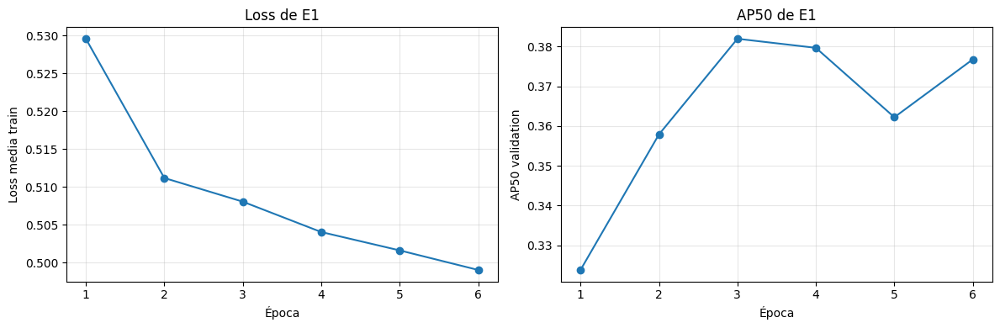

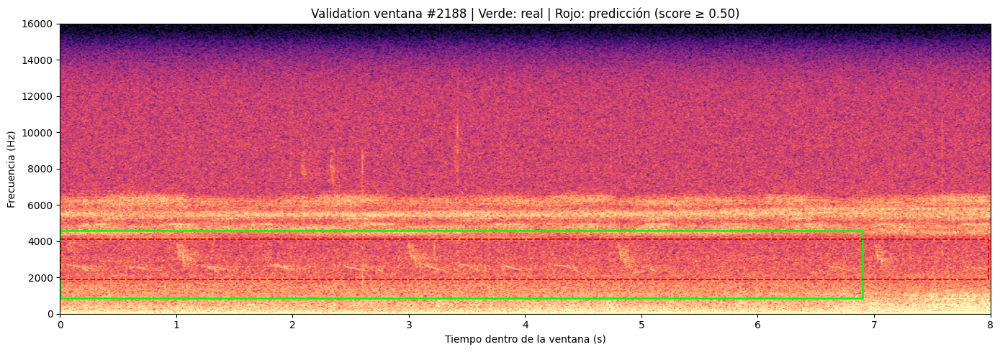

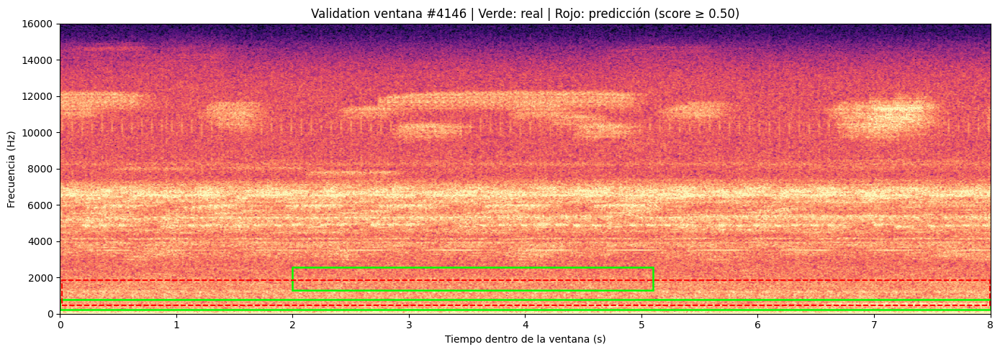

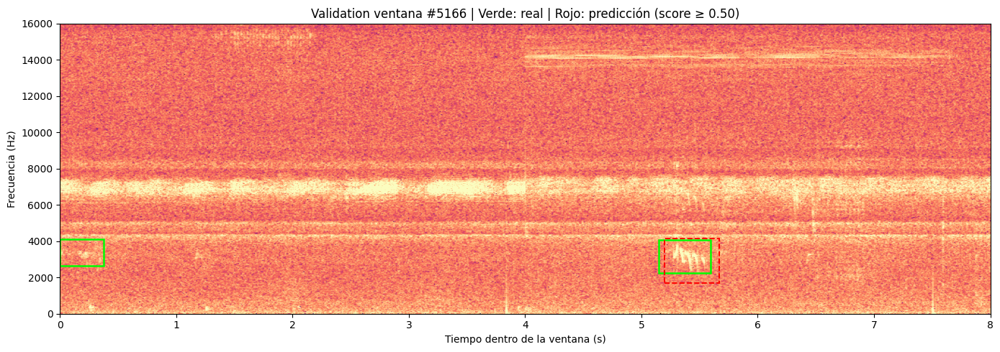

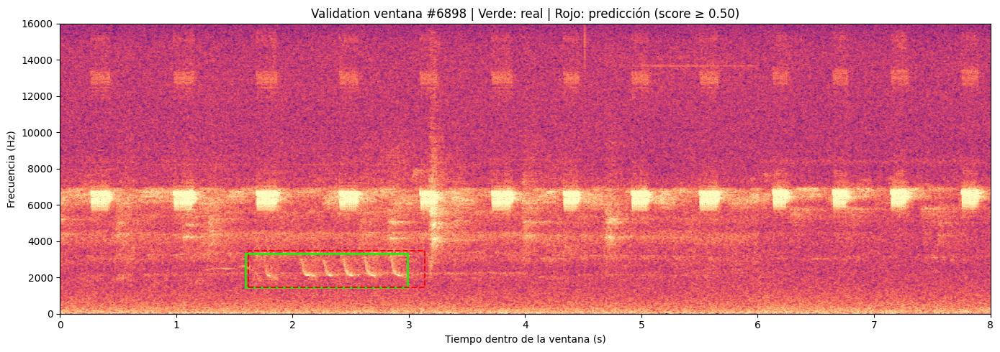

In [ ]:
# curvas de entrenamiento y ejemplos de detecciones. Puede ejecutarse en CPU
ruta_historial_eval = DIR_E1_EVAL / "historial.csv"
if ruta_historial_eval.is_file():
    historial_eval = pd.read_csv(ruta_historial_eval)
    display(historial_eval)
    fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
    ejes[0].plot(historial_eval["epoca"], historial_eval["loss_train"], marker="o")
    ejes[0].set(xlabel="Época", ylabel="Loss media train", title="Loss de E1")
    ejes[1].plot(historial_eval["epoca"], historial_eval["ap50_validation"], marker="o")
    ejes[1].set(xlabel="Época", ylabel="AP50 validation", title="AP50 de E1")
    for eje in ejes:
        eje.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

if "payload_eval" not in globals():
    payload_eval = torch.load(RUTA_PREDICCIONES_EVAL, map_location="cpu", weights_only=True)

for ejemplo in payload_eval["ejemplos"]:
    imagen = ejemplo["imagen"].squeeze(0).numpy()
    alto, ancho = imagen.shape
    _, ax = plt.subplots(figsize=(14, 5))
    ax.imshow(imagen, origin="lower", aspect="auto", extent=[0, VENTANA_S_EVAL if "VENTANA_S_EVAL" in globals() else 8, 0, 16000], cmap="magma", vmin=0, vmax=1)

    for caja in ejemplo["gt_boxes"].numpy():
        x0, y0, x1, y1 = caja
        ax.add_patch(Rectangle((x0 * 8 / ancho, y0 * 16000 / alto), (x1 - x0) * 8 / ancho, (y1 - y0) * 16000 / alto, fill=False, edgecolor="lime", linewidth=1.8))

    for caja, score in zip(ejemplo["boxes"].numpy(), ejemplo["scores"].numpy()):
        if score < 0.50:
            continue
        x0, y0, x1, y1 = caja
        ax.add_patch(Rectangle((x0 * 8 / ancho, y0 * 16000 / alto), (x1 - x0) * 8 / ancho, (y1 - y0) * 16000 / alto, fill=False, edgecolor="red", linewidth=1.4, linestyle="--"))

    ax.set(title=f"Validation ventana #{ejemplo['indice']} | Verde: real | Rojo: predicción (score ≥ 0.50)", xlabel="Tiempo dentro de la ventana (s)", ylabel="Frecuencia (Hz)")
    plt.tight_layout()
    plt.show()

## Lectura de las gráficas y cierre del experimento 1

La curva de pérdida muestra cómo evoluciona el ajuste sobre entrenamiento, la curva de AP50 indica cómo evoluciona la localización en validación. No tienen la misma escala ni optimizan exactamente la misma propiedad. En E1, la pérdida siguió bajando, pero el mejor AP50 se obtuvo en la época 3, motivo por el cual ese checkpoint es el seleccionado.

En los espectrogramas, las cajas verdes continuas representan anotaciones reales y las rojas discontinuas predicciones con confianza ≥ 0,50. Conviene observar eventos omitidos, detecciones espurias, cajas demasiado amplias o estrechas y vocalizaciones superpuestas. Los ejemplos visualizados son una inspección cualitativa, no una estimación estadística del desempeño total.

Estado del experimento: E1 queda entrenado y evaluado sobre ventanas positivas de validación. La evaluación de FP/h en audio continuo y la comparación común con las demás arquitecturas se realizarán posteriormente, no es necesario volver a entrenar E1 para ello.

## Probar espectogramas aleatorios

ejecutar las primeras 5 celdas de la sección de Evaluación del detector E1

desde ``%pip -q install "kagglehub>=1.0.0" "torchmetrics[detection]>=1.4,<2"`` hasta ``class DatasetValidacionE1(Dataset):``

100%|██████████| 18.6M/18.6M [00:00<00:00, 92.2MB/s]


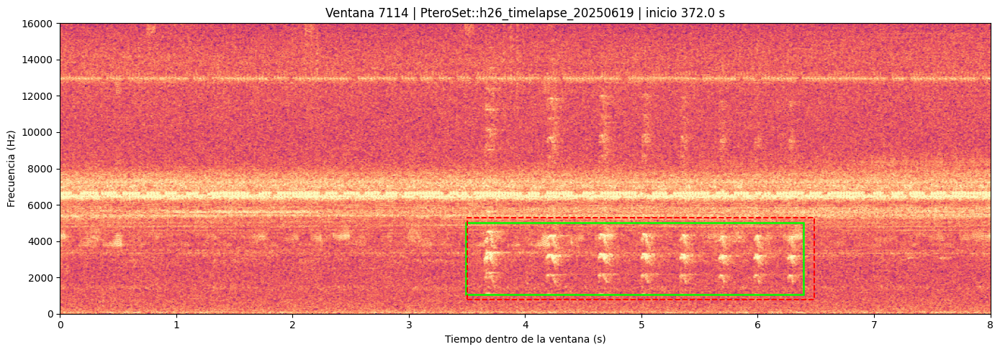

100%|██████████| 108M/108M [00:01<00:00, 112MB/s]


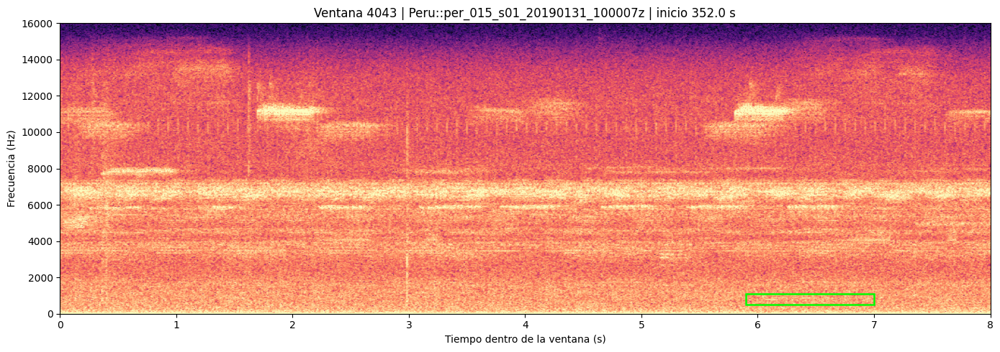

100%|██████████| 20.2M/20.2M [00:00<00:00, 95.2MB/s]


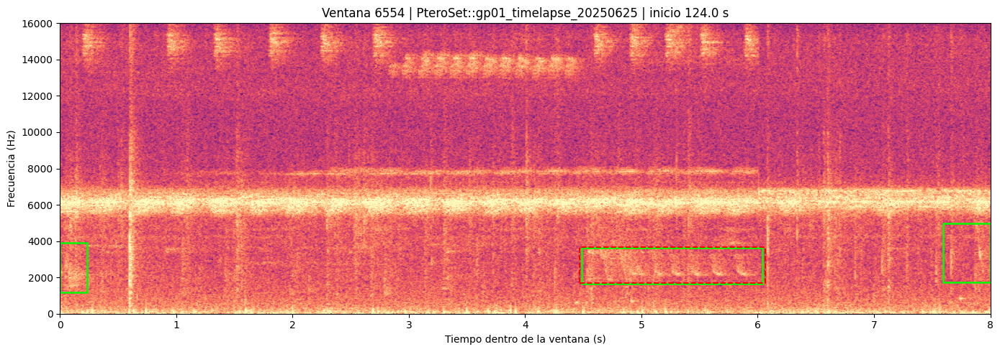

100%|██████████| 18.7M/18.7M [00:00<00:00, 131MB/s]


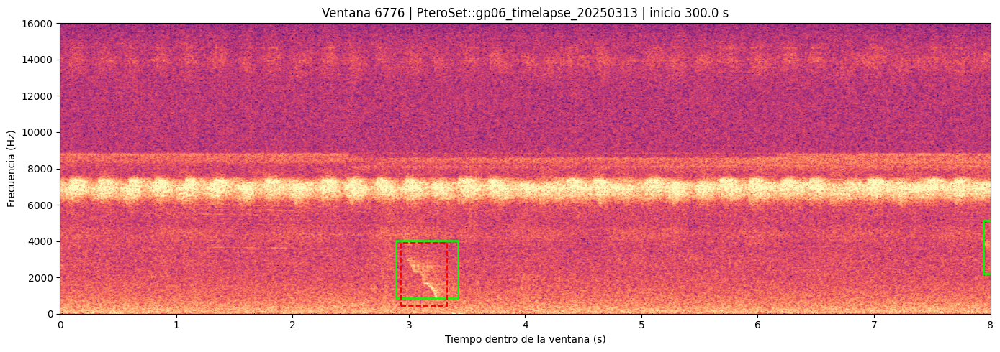

In [9]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

payload = torch.load(RUTA_PREDICCIONES_EVAL, map_location="cpu", weights_only=True)
SEMILLA = None
CANTIDAD = 4
UMBRAL = 0.50

indices = np.random.default_rng(SEMILLA).choice(len(dataset_eval), size=CANTIDAD, replace=False)

for idx in indices:
    idx = int(idx)
    imagen, _ = dataset_eval[idx]
    pred = payload["predicciones"][idx]
    fila = ventanas_positivas_eval.iloc[idx]
    espectrograma = imagen.squeeze(0).numpy()
    alto, ancho = espectrograma.shape
    fig, ax = plt.subplots(figsize=(14, 5))
    ax.imshow(espectrograma, origin="lower", aspect="auto", extent=[0, 8, 0, 16000], cmap="magma", vmin=0, vmax=1)

    for caja in pred["gt_boxes"].numpy():
        x0, y0, x1, y1 = caja
        ax.add_patch(Rectangle((x0 * 8 / ancho, y0 * 16000 / alto), (x1 - x0) * 8 / ancho, (y1 - y0) * 16000 / alto, fill=False, edgecolor="lime", linewidth=1.8))

    for caja, score in zip(pred["boxes"].numpy(), pred["scores"].numpy()):
        if score < UMBRAL:
            continue

        x0, y0, x1, y1 = caja
        ax.add_patch(Rectangle((x0 * 8 / ancho, y0 * 16000 / alto), (x1 - x0) * 8 / ancho, (y1 - y0) * 16000 / alto, fill=False, edgecolor="red", linewidth=1.4, linestyle="--"))

    ax.set(title=f"Ventana {idx} | {fila.recording_uid} | inicio {fila.inicio_s:.1f} s", xlabel="Tiempo dentro de la ventana (s)", ylabel="Frecuencia (Hz)")
    plt.tight_layout()
    plt.show()